# Where a coding ban takes effect in Qwen3-8B: route-test demo

**Artifact:** experiment-16 (`art__5akZ9W9iZM4`) of *Prompt bans substitute, not just subtract*.

A prompt ban such as *"Do not use a hash set of seen values for this task."* makes Qwen3-8B (bf16, thinking off) write a different algorithm. This experiment asks **which internal route carries that effect**, on the 12 frozen coding tasks of the bench. Every arm of a CRN slot `(task, template, k)` is sampled with the same **common random numbers** (CRN): one fixed stream of uniforms, turned into tokens by inverse-CDF sampling. The arms are built by **splicing KV caches** by position, so they differ only in the cache their generated tokens read:

| arm | cache read by the generated tokens | what it tests |
|---|---|---|
| `a` | full ban prompt | clean endpoint |
| `b` | token-length-matched neutral twin (*"Do not use fire for this task. . ."*) | corrupted endpoint |
| `c` | twin condition segment + ban task-spec states | **prompt route**: do the later prompt states alone carry the ban? |
| `d` | ban condition segment + twin task-spec states | **direct route**: is generated tokens reading the ban itself enough? |
| `K0` | full ban, but the condition span is invisible to every generated token | removal of the direct route |

Each generated program is labelled with its mechanism: runtime trace first, AST second, and a blind LLM judge on disagreement. For a task with default mechanism D, `s_X` is the share of arm X's attempts labelled D. The route fractions are

$$F_\text{prompt}=\frac{s_b-s_c}{s_b-s_a},\quad F_\text{direct}=\frac{s_b-s_d}{s_b-s_a},\quad I=1-F_\text{prompt}-F_\text{direct},\quad F_\text{K0}=\frac{s_b-s_{K0}}{s_b-s_a}.$$

**Full-run result (13,030 samples).**
- **Gate:** only 5 of the 12 tasks pass the gate, i.e. the ban moves the model.
- **C2a disconfirmed:** the claim "the prompt route carries >= 2/3 of the ban" fails. Pooled F_prompt = 0.61 and F_direct = 0.74.
- **Task-dependent mechanism:**
  - T03/T10: either route alone suffices.
  - T05/T06: the ban works through the direct route.
  - T13: both routes are needed.

### What this notebook runs (CPU, a few minutes)
1. **The S9 analysis code** (`src/analysis/analysis.py`) on a curated subset: 100 CRN slots of the `route_arms` dataset, i.e. 500 labelled programs by Qwen3-8B. It covers the gate, shares and route fractions, with a hierarchical bootstrap, BCa and leave-one-task-out jackknife intervals. It also runs leave-one-template-out, a Bayesian mixed GLM, the C2a verdict, CRN flip tables and first divergence, landings and C2c.
2. **The original HF engine** (`src/engine.py`) on one CRN slot set, with a small Qwen3 model on CPU. This is the same prefill / KV-splice / span-drop / CRN-sampling code that ran Qwen3-8B on an L4 GPU. It uses the frozen prompt ids and the exact uniforms of the real run, and shows the Qwen3-8B rows of those slots beside its own output.

Some stages are not re-run: the Qwen3-8B GPU queue (about 1.8 GPU-hours), the frozen labellers (bench harness + LLM judge) and the stages that need the upstream bench folders. Their outputs come in as the labelled `route_arms` data.

### `method.py` stages and where they appear here
| `uv run method.py <stage>` | what it does | in this notebook |
|---|---|---|
| `s0`, `recheck`, `s1`, `s2`, `tests` | input snapshot + bench sha256, labeller re-check, prompts with alignment asserts, frozen forecasts (n-grams, veto classes), CPU tests | not run; their frozen outputs (prompt ids, n-grams, veto classes, catalogues) ship in the data |
| `gpu` + `label` | GPU queue: CRN-coupled sampling of every arm with Qwen3-8B, plus the streaming labeller | section 5 runs the engine on one slot set with a small model; the labels ship in the data |
| `close1` | hash-chain commit of the analysis code before any ban sample | not applicable |
| `analysis` | S9 analysis | sections 2-4, on the subset |
| `figures`, `outputs`, `audit` | figures, `method_out.json`, independent re-derivation | section 6 (visualisation, demo vs. full run) |

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru -- NOT pre-installed on Colab, always install
_pip('loguru==0.7.3')

# numpy, pandas, scipy, statsmodels, matplotlib, torch, transformers -- pre-installed on Colab, install locally only
# (torch: Colab's CPU build, from the PyTorch CPU index, so a local run does not pull the CUDA wheels)
if 'google.colab' not in sys.modules:
    _pip('--index-url', 'https://download.pytorch.org/whl/cpu', 'torch==2.9.0+cpu')
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'scipy==1.16.3', 'statsmodels==0.14.6', 'matplotlib==3.10.0',
         'transformers==5.0.0', 'tokenizers==0.22.2', 'huggingface_hub==1.4.0')

In [2]:
# original imports of the code used below (src/cfg.py, src/engine.py, src/gpu.py, src/analysis/analysis.py)
import collections
import contextlib
import gc
import hashlib
import json
import math
import os
import re
import sys
import time
from pathlib import Path
from typing import Any, Callable, Iterable, Iterator

import numpy as np
import torch
from loguru import logger
from scipy import stats

# notebook additions: tables and figures; silence two benign warnings the original code also raises
# (nanmean over bootstrap draws where every task has s_b == s_a; Spearman on a constant bootstrap resample)
import warnings

import matplotlib.pyplot as plt
import pandas as pd

warnings.filterwarnings("ignore", message="Mean of empty slice", category=RuntimeWarning)
warnings.filterwarnings("ignore", message="An input array is constant")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
print("torch", torch.__version__, "| numpy", np.__version__, "| cuda available:", torch.cuda.is_available())

torch 2.9.0+cpu | numpy 2.0.2 | cuda available: False


In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-3/experiment-16/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
meta = data["metadata"]
examples = data["datasets"][0]["examples"]  # the route_arms dataset: one example per CRN slot (task, template, k)
print(meta["description"])
print("source:   ", meta["source"])
print("selection:", meta["selection_rule"])
print(f"{len(examples)} CRN slots | full-run model: {meta['model']} ({meta['dtype']}) | {meta['decoding']}")
print("example:", {k: v for k, v in examples[0].items() if k != "metadata_token_ids"})

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Curated demo subset of the route_arms dataset of 'Where a coding ban takes effect in Qwen3-8B' (CRN-coupled KV-splice route test on 12 frozen bench tasks).
source:    full_method_out.json -> datasets[route_arms] (+ per-arm token ids from data/samples.jsonl)
selection: gated tasks ['T03', 'T06', 'T05', 'T10', 'T13']: slots k < 3 of every template; first 5 non-gated tasks in STAGE_A order ['T04', 'R1', 'T08', 'R3', 'R6']: slot k < 1 of every template
100 CRN slots | full-run model: Qwen/Qwen3-8B (bfloat16) | T=1.0, top-p 1.0, no top-k, max 1024 new tokens, CRN inverse-CDF sampling
example: {'input': "task T03 | template W1 | slot k=0 | ban segment: 'Do not use a full sort for this task.' | neutral twin: 'Do not use man for this task. . .'", 'output': 'quickselect', 'metadata_task': 'T03', 'metadata_template': 'W1', 'metadata_k': 0, 'metadata_default': 'full_sort', 'metadata_gated': True, 'metadata_a_passe

## Config

Every tunable parameter is set here, and each comment gives the original value.

- **Resampling counts:** the bootstrap, permutation and resampling-null counts are at the original values. They cost seconds at this data size.
- **`N_SLOTS`:** must match the demo data, which has 3 CRN slots per template on the gated tasks. The full run has 20.
- **Engine model:** the engine cell runs a small Qwen3 model. It shares Qwen3-8B's tokenizer, so the frozen prompt ids and the CRN uniforms of the real run apply unchanged. Set `ENGINE_MODEL_ID = "Qwen/Qwen3-8B"` (with `ENGINE_REVISION` = the original revision, `ENGINE_DTYPE = torch.bfloat16` and a GPU with more than 17 GB) to run the original model.

Functions take some of these values as defaults when they are defined. After editing this cell, re-run the notebook from here.

In [5]:
# ------------------------------------------------------------------ analysis (src/analysis/analysis.py, src/cfg.py)
N_SLOTS = 3            # CRN slots k per template in the demo data (original: 20 = cfg.N_PER_TEMPLATE)
N_BOOT = 10000         # hierarchical task -> template -> slot bootstrap reps, pooled F (= original cfg.N_BOOT)
N_BOOT_TASK = 4000     # template -> slot bootstrap reps per task (= original per_task_route default)
N_PERM = 100000        # permutations of the one-sided C2c Spearman test (= original cfg.N_PERM)
N_BOOT_RHO = 4000      # task bootstrap reps of the C2c rho interval (= original)
LANDING_N_REP = 2000   # resamples of the landing JS null (= original landing_null default)
RNG_SEED = 20261020    # cfg.RNG_SEED (unchanged)

# ------------------------------------------------------------------ engine (src/engine.py, src/gpu.py)
RUN_ENGINE = True                      # False skips the model download and the live CRN slots (section 5)
ENGINE_MODEL_ID = "Qwen/Qwen3-0.6B"    # original: "Qwen/Qwen3-8B" (cfg.MODEL_ID); same tokenizer and chat template
ENGINE_REVISION = "c1899de289a04d12100db370d81485cdf75e47ca"  # pinned; original: "b968826d9c46dd6066d109eabc6255188de91218"
ENGINE_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"  # original: one NVIDIA L4 (23 GB)
ENGINE_DTYPE = torch.float32           # original: torch.bfloat16
ENGINE_MAX_NEW = 160                   # max new tokens per row; rows stop at their closing code fence, T06 programs need
                                       # < 80 (original: 1024 -- a never-closing row would cost minutes per batch on CPU)
ENGINE_N_SLOTS = 3                     # CRN slots k of the engine slot set to sample: all k = 0, 1, 2 in the data (original: 20 per template)

## 1. Frozen protocol constants and helpers (`src/cfg.py`)

These are the bench tasks in run order (`STAGE_A`) and each task's **default mechanism** (what Qwen3-8B writes without a ban). They are followed by the five ban templates W1-W5 (ban / mention / neutral wording) and the pre-registered decision thresholds.

The neutral twin of a ban fills the template's `{N}` slot with a concrete noun such as *fire*. It is padded with `" ."` to exactly the ban's token length, so positions line up and KV caches can be spliced position by position.

The helpers are copied verbatim. `stable_seed` is exp8's sha256-based seed, which keys the CRN uniform streams. Only the file-based logging sink and the file paths are dropped.

In [6]:
# ------------------------------------------------------------------------------------------------ model
MODEL_ID = "Qwen/Qwen3-8B"
MODEL_REVISION = "b968826d9c46dd6066d109eabc6255188de91218"

N_LAYERS = 36
IM_END = 151645
ENDOFTEXT = 151643
MAX_NEW_TOKENS = 1024
TEMPERATURE = 1.0
DECODING = "T1.0_topp1.0_topk-off_max1024_thinkoff"
TEMPLATE_TAIL = "<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\n"
BATCH = 20  # constant batch shape for every sampled batch (two CRN blocks of 10); see deviations

# ------------------------------------------------------------------------------------------------ bench
STAGE_A = ["T03", "T04", "T06", "T05", "T10", "R1", "T08", "R3", "T13", "R6", "T14", "T11"]
TASK_DIR = {"T03": "T03_kth_smallest", "T04": "T04_substring_search", "T06": "T06_find_duplicate",
            "T05": "T05_two_sum", "T10": "T10_connected_components", "R1": "R1_non_overlapping_intervals",
            "T08": "T08_fibonacci", "R3": "R3_topological_order", "T13": "T13_merge_intervals",
            "R6": "R6_first_last_position", "T14": "T14_top_k_frequent", "T11": "T11_longest_increasing_subsequence"}
DEFAULT = {"T03": "full_sort", "T04": "naive", "T06": "hash_set", "T05": "hash_map", "T10": "union_find",
           "R1": "greedy_end", "T08": "iteration", "R3": "kahn", "T13": "sort_sweep", "R6": "binary_search",
           "T14": "sort_by_count", "T11": "quadratic_dp"}
PATH_TASKS = ("t1", "t2")
PATH_DEFAULT = {"t1": "bfs", "t2": "dijkstra"}
PATH_SUB = {"t1": "dfs", "t2": "bf_spfa"}
ALL_TASKS = STAGE_A + list(PATH_TASKS)

# W1-W5 (ban, mention, neutral) verbatim from the shared protocol v2 (exp8 cfg.TEMPLATES).
TEMPLATES: dict[str, tuple[str, str, str]] = {
    "W1": ("Do not use {X} for this task.", "You could use {X} for this task.", "Do not use {N} for this task."),
    "W2": ("Your solution must not rely on {X}.", "Your solution may rely on {X}.", "Your solution must not rely on {N}."),
    "W3": ("Avoid {X} entirely.", "Consider {X} first.", "Avoid {N} entirely."),
    "W4": ("{X} is not allowed here.", "{X} is allowed here.", "{N} is not allowed here."),
    "W5": ("Write a correct solution that does not use {X}.", "Write a correct solution that may use {X}.",
           "Write a correct solution that does not use {N}."),
}
TEMPLATE_IDS = list(TEMPLATES.keys())
FILLER = " ."  # exp7 frozen neutral-twin padding filler
N_PER_TEMPLATE = 20
BLOCK = 10

THRESHOLDS = {
    "F_confirm": 2.0 / 3.0, "F_ci_lower": 0.5, "F_direct_disconfirm": 1.0 / 3.0,
    "gate_avoidance": 0.5, "gate_min_nondefault": 20,
    "veto_low_direct": 0.8, "veto_high_direct": 0.5, "pred_low_direct_F": 0.15, "pred_high_direct_F": 0.25,
    "veto_min_fire_rate": 0.5, "c2c_hit_fraction": 2.0 / 3.0, "c2c_disconfirm_hit": 0.5, "c2c_alpha": 0.05,
    "ngram_presence": 0.8, "coveto": 0.5, "reemerge": 0.2, "screen_min_nond": 20, "placebo_tol": 0.1,
    "c2b_eligible_V": 0.5, "c2b_task_share": 2.0 / 3.0,
}
# N_BOOT, N_PERM and RNG_SEED are set in the config cell (cfg.py: 10000, 100000, 20261020)
PRED_DIR = Path("predictions")  # not shipped with the demo: the frozen predictions are read from data["metadata"]


# ------------------------------------------------------------------------------------------------ utils
def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    # original also writes logs/<name>.log: logger.add(str(LOG_DIR / f"{name}.log"), rotation="30 MB", level="DEBUG")


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8")).hexdigest()


def stable_seed(*parts: Any) -> int:
    """exp8: deterministic 63-bit seed from arbitrary parts (sha256 of their '|'-joined repr)."""
    return int(hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest(), 16) % (2 ** 63)


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


def wilson_ci(k: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


def default_of(task: str) -> str:
    return PATH_DEFAULT[task] if task in PATH_TASKS else DEFAULT[task]


setup_logging("demo")
print({t: DEFAULT[t] for t in STAGE_A})

{'T03': 'full_sort', 'T04': 'naive', 'T06': 'hash_set', 'T05': 'hash_map', 'T10': 'union_find', 'R1': 'greedy_end', 'T08': 'iteration', 'R3': 'kahn', 'T13': 'sort_sweep', 'R6': 'binary_search', 'T14': 'sort_by_count', 'T11': 'quadratic_dp'}


## 2. Labelled rows (replaces `analysis.load_rows()` on `data/samples.jsonl`)

In the original pipeline the GPU queue writes one raw row per generated program. The label worker runs the frozen labellers, and `data/samples.jsonl` ends up with one labelled row per `uid = task|arm|template|k`.

The demo data stores the same information per CRN slot:
- `output` is the arm-`a` label.
- `predict_<arm>` is `'<mechanism>|pass'` or `'<mechanism>|fail'` for the other arms.
- `metadata_token_ids` holds the generated ids of each arm.

`load_rows()` below rebuilds exactly the fields the analysis reads. An arm marked `not_run` gets no row, as in the original. `catalogue()` is `forecast_s2.catalogue()` reading the per-task mechanism lists from the data instead of `bench/<task>/spec.json`.

In [7]:
EXCL = ("invalid", "no_code", "disputed")
ROUTE_ARMS = ("a", "b", "c", "d")


# ------------------------------------------------------------------------------------------------ helpers
def load_rows() -> list[dict[str, Any]]:
    # notebook version: rebuild one labelled row per (task, arm, template, k) from the route_arms examples
    # (original: rows = read_jsonl(SAMPLES)); an arm marked 'not_run' has no row, as in data/samples.jsonl
    rows = []
    for e in examples:
        t, w, k = e["metadata_task"], e["metadata_template"], e["metadata_k"]
        labs = {"a": (e["output"], bool(e["metadata_a_passed"]))}
        for a in ("b", "c", "d", "K0"):
            if e[f"predict_{a}"] != "not_run":
                lab, _, res = e[f"predict_{a}"].partition("|")
                labs[a] = (lab, res == "pass")
        for a, (lab, passed) in labs.items():
            rows.append({"uid": f"{t}|{a}|{w}|{k}", "stage": "demo", "task": t, "template": w, "w": w, "k": k,
                         "arm": a, "label": lab, "passed": passed, "token_ids": e["metadata_token_ids"].get(a)})
    seen = {}
    for r in rows:  # last label wins if a uid was relabelled
        seen[r["uid"]] = r
    return list(seen.values())


def catalogue(task: str) -> list[str]:
    # original: forecast_s2.catalogue() -> [c["mode"] for c in read_json(BENCH / TASK_DIR[task] / "spec.json")["catalogue"]]
    return meta["catalogue"][task]


def survivors(task: str) -> list[str]:
    return [m for m in catalogue(task) if m != default_of(task)] + ["other"]


rows = load_rows()
bench_rows = [r for r in rows if r["task"] in STAGE_A and r["stage"] not in ("U9",)]  # as in run_analysis()
demo_tasks = [t for t in STAGE_A if any(r["task"] == t for r in bench_rows)]
print(f"{len(rows)} labelled rows over {len(demo_tasks)} tasks; rows per task x arm:")
print(pd.crosstab(pd.Series([r["task"] for r in rows], name="task"), pd.Series([r["arm"] for r in rows], name="arm"))
      .reindex(demo_tasks))
print("\none CRN slot (T06, W1, k=1) -- every arm read the same uniforms:")
for r in rows:
    if (r["task"], r["template"], r["k"]) == ("T06", "W1", 1):
        print(f"  arm {r['arm']:3s} label={r['label']:15s} passed={r['passed']}  n_tokens={len(r['token_ids'])}")

500 labelled rows over 10 tasks; rows per task x arm:
arm   K0   a   b   c   d
task                    
T03   15  15  15  15  15
T04    5   5   5   5   5
T06   15  15  15  15  15
T05   15  15  15  15  15
T10   15  15  15  15  15
R1     5   5   5   5   5
T08    5   5   5   5   5
R3     5   5   5   5   5
T13   15  15  15  15  15
R6     5   5   5   5   5

one CRN slot (T06, W1, k=1) -- every arm read the same uniforms:
  arm a   label=index_marking   passed=True  n_tokens=53
  arm b   label=hash_set        passed=True  n_tokens=39
  arm c   label=hash_set        passed=True  n_tokens=34
  arm d   label=index_marking   passed=True  n_tokens=53
  arm K0  label=hash_set        passed=True  n_tokens=34


## 3. Gate: does the ban move the model at all? (`gpu.compute_gate`)

The route analysis only makes sense where the full ban changes the program. The pre-registered gate needs two things from arm `a`: **avoidance** `1 - s_a >= 0.5`, and **at least 20 non-default attempts** (out of 100 CRN slots per task).

In the original, `compute_gate()` runs inside the GPU queue on the labelled arm-a rows and writes `results/gate.json`. `run_analysis()` then reads that file. The demo does the same:
- `compute_gate()` runs verbatim on the subset. `labelled_uids()` returns the demo rows instead of reading `data/samples.jsonl`.
- The confirmatory analysis uses the **frozen gate** shipped in the data, i.e. `results/gate.json` from all 100 arm-a rows per task.

The subset has at most 15 arm-a rows per task, so no task can reach 20 non-default attempts here. The subset's avoidance column still shows the same split as the full run.

In [8]:
ATTEMPT_EXCLUDE = ("invalid", "no_code", "disputed")


# ------------------------------------------------------------------------------------------------ labels
def labelled_uids() -> dict[str, dict[str, Any]]:
    return {r["uid"]: r for r in rows}  # original: {r["uid"]: r for r in read_jsonl(SAMPLES)}


def share_default(rows: list[dict[str, Any]], task: str) -> tuple[int, int]:
    att = [r for r in rows if r["label"] not in ATTEMPT_EXCLUDE]
    return sum(r["label"] == default_of(task) for r in att), len(att)


def compute_gate(tasks: list[str]) -> dict[str, Any]:
    lab = labelled_uids()
    out = {}
    for t in tasks:
        rows = [r for r in lab.values() if r["task"] == t and r["arm"] == "a"]
        nd, na = share_default(rows, t)
        s_a = nd / na if na else float("nan")
        out[t] = {"s_a": s_a, "avoidance": 1 - s_a, "n_attempted": na, "n_nondefault": na - nd, "n_rows": len(rows),
                  "gated": bool(na and (1 - s_a) >= THRESHOLDS["gate_avoidance"]
                                and (na - nd) >= THRESHOLDS["gate_min_nondefault"])}
    return out


gate_demo = compute_gate(demo_tasks)

# run_analysis(): gate = read_json(RESULTS_DIR / "gate.json"); failed = labeller_recheck["failed_tasks"]
gate = meta["gate"]  # frozen results/gate.json (all 100 arm-a rows per task)
failed = set()       # results/labeller_recheck.json: failed_tasks = [] (every bench labeller passed its re-check)
gated = [t for t in STAGE_A if gate.get(t, {}).get("gated") and t not in failed]

gate_tbl = pd.DataFrame({t: {"default": DEFAULT[t],
                             "full: avoidance": gate[t]["avoidance"], "full: n_nondefault/100": gate[t]["n_nondefault"],
                             "full: gated": gate[t]["gated"],
                             "demo: avoidance": gate_demo[t]["avoidance"] if t in gate_demo else None,
                             "demo: n_nondefault": gate_demo[t]["n_nondefault"] if t in gate_demo else None,
                             "demo: n_attempted": gate_demo[t]["n_attempted"] if t in gate_demo else None}
                         for t in STAGE_A}).T
print(gate_tbl.to_string(float_format=lambda x: f"{x:.2f}"))
print("\ngated (frozen gate, used below):", gated)

           default full: avoidance full: n_nondefault/100 full: gated demo: avoidance demo: n_nondefault demo: n_attempted
T03      full_sort            0.99                     99        True            1.00                 15                15
T04          naive            0.42                     42       False            0.60                  3                 5
T06       hash_set            0.79                     79        True            0.80                 12                15
T05       hash_map            0.83                     83        True            0.87                 13                15
T10     union_find            1.00                    100        True            1.00                 15                15
R1      greedy_end            0.00                      0       False            0.00                  0                 5
T08      iteration            0.31                     31       False            0.00                  0                 5
R3            ka

## 4. S9 analysis (`src/analysis/analysis.py`)

The analysis code was committed in a hash chain *before any ban sample existed* (commit #1). The functions below are copied from it. The only changes are reading from the loaded data instead of files, and the resampling counts from the config cell.

### 4.1 Default share per task and arm (9.1)

`share()` counts, among the *attempted* programs (not `invalid`, `no_code` or `disputed`), the fraction labelled with the task's default mechanism, with a Wilson 95% interval. It also records the **landing**, i.e. which other mechanism the model wrote instead, together with pass rates and Hill diversity.

For a working ban, `s_a` (full ban) is far below `s_b` (neutral twin). Where `s_c` and `s_d` fall between the two tells which route carries the effect.

In [9]:
def hill1(labels: list[str]) -> float:
    if not labels:
        return float("nan")
    c = np.array(list(collections.Counter(labels).values()), float)
    p = c / c.sum()
    return float(np.exp(-(p * np.log(p)).sum()))


def share(rows: list[dict[str, Any]], task: str) -> dict[str, Any]:
    D = default_of(task)
    att = [r for r in rows if r["label"] not in EXCL]
    nd = sum(r["label"] == D for r in att)
    n = len(att)
    lo, hi = wilson_ci(nd, n) if n else (float("nan"), float("nan"))
    nond = [r for r in att if r["label"] != D]
    land = collections.Counter(r["label"] for r in nond)
    corr = collections.Counter(r["label"] for r in nond if r.get("passed"))
    return {"n_rows": len(rows), "n_attempted": n, "n_default": nd, "s": nd / n if n else float("nan"),
            "ci95": [lo, hi], "landing": dict(land), "modal_survivor": land.most_common(1)[0][0] if land else None,
            "correct_landing": dict(corr),
            "other_share": (sum(r["label"] == "other" for r in att) / n) if n else float("nan"),
            "invalid_share": (sum(r["label"] in ("invalid", "no_code") for r in rows) / len(rows)) if rows else float("nan"),
            "disputed": sum(r["label"] == "disputed" for r in rows),
            "pass_rate": float(np.mean([bool(r.get("passed")) for r in rows])) if rows else float("nan"),
            "hill_cc": hill1([r["label"] for r in att if r.get("passed")]),
            "hill_cc_nondefault": hill1([r["label"] for r in nond if r.get("passed")])}


def by(rows: list[dict[str, Any]], *keys: str) -> dict[tuple, list[dict[str, Any]]]:
    out: dict[tuple, list] = collections.defaultdict(list)
    for r in rows:
        out[tuple(r[k] for k in keys)].append(r)
    return out


# ------------------------------------------------------------------------------------------------ 9.1
def shares_table(rows: list[dict[str, Any]]) -> dict[str, Any]:
    out: dict[str, Any] = {}
    g = by(rows, "task", "arm")
    for (t, a), lst in sorted(g.items()):
        out.setdefault(t, {})[a] = share(lst, t)
        per_w = {}
        for w in TEMPLATE_IDS:
            sub = [r for r in lst if r["template"] == w]
            if sub:
                s = share(sub, t)
                per_w[w] = {k: s[k] for k in ("n_attempted", "n_default", "s", "modal_survivor", "pass_rate")}
        out[t][a]["per_template"] = per_w
    return out


shares = shares_table(bench_rows)
ARMS5 = ("a", "b", "c", "d", "K0")
share_tbl = pd.DataFrame({t: {f"s_{a}": shares[t][a]["s"] for a in ARMS5 if a in shares[t]} for t in demo_tasks}).T
share_tbl["n/arm"] = [shares[t]["a"]["n_attempted"] for t in demo_tasks]
share_tbl["arm-a modal survivor"] = [shares[t]["a"]["modal_survivor"] for t in demo_tasks]
share_tbl["gated"] = [t in gated for t in demo_tasks]
print(share_tbl.to_string(float_format=lambda x: f"{x:.2f}"))

     s_a  s_b  s_c  s_d  s_K0  n/arm arm-a modal survivor  gated
T03 0.00 0.93 0.00 0.20  0.00     15          quickselect   True
T04 0.40 1.00 1.00 0.80  1.00      5                  bmh  False
T06 0.20 1.00 1.00 0.27  1.00     15        index_marking   True
T05 0.13 1.00 0.73 0.20  0.67     15          brute_force   True
T10 0.00 1.00 0.00 0.20  0.00     15                  bfs   True
R1  1.00 1.00 1.00 1.00  1.00      5                 None  False
T08 1.00 1.00 1.00 1.00  1.00      5                 None  False
R3  1.00 1.00 1.00 1.00  1.00      5                 None  False
T13 0.33 1.00 0.73 1.00  0.67     15                other   True
R6  0.80 0.80 1.00 0.80  1.00      5                other  False


### 4.2 Route fractions with CRN-respecting resampling (9.2)

`slot_arrays()` builds two 0/1 tensors indexed `[task, template, slot k, arm]`: `banned` (the program is the default mechanism) and `att` (an attempt was made). The pooled fractions are a **ratio of sums** over tasks, not a mean of per-task ratios.

All intervals resample *whole CRN slots*, keeping every arm of a slot together, because the arms share their uniforms:
- **Hierarchical bootstrap:** task → template → slot.
- **Leave-one-task-out jackknife:** with 3-5 gated tasks the pooled estimate is low-cluster. Pre-registered fallback F5, a logged amendment, makes the jackknife t-interval the *primary* interval.
- **BCa:** bias-corrected and accelerated, using the jackknife for acceleration.

C2a decision rule:
- **SUPPORTED:** `F_prompt >= 2/3` with a CI lower bound > 1/2, and not `F_direct >= 1/3`.
- **DISCONFIRMED:** `F_direct >= 1/3` without support.
- **MIXED:** otherwise.

The only code change: `slot_arrays()` used `K = 20` slots per template, and here it uses `N_SLOTS` from the config.

In [10]:
# ------------------------------------------------------------------------------------------------ 9.2
def slot_arrays(rows: list[dict[str, Any]], tasks: list[str], arms: tuple[str, ...] = ROUTE_ARMS) -> dict[str, Any]:
    """banned[t, w, k, arm] in {0,1}, att[t, w, k, arm] in {0,1} (attempted)."""
    T, Wn, K, A = len(tasks), len(TEMPLATE_IDS), N_SLOTS, len(arms)  # original: K = 20
    ban = np.zeros((T, Wn, K, A), np.int8)
    att = np.zeros((T, Wn, K, A), np.int8)
    idx = {(r["task"], r["template"], r["k"], r["arm"]): r for r in rows}
    for i, t in enumerate(tasks):
        D = default_of(t)
        for j, w in enumerate(TEMPLATE_IDS):
            for k in range(K):
                for a_i, a in enumerate(arms):
                    r = idx.get((t, w, k, a))
                    if r is not None and r["label"] not in EXCL:
                        att[i, j, k, a_i] = 1
                        ban[i, j, k, a_i] = int(r["label"] == D)
    return {"ban": ban, "att": att, "tasks": tasks, "arms": arms}


def fractions_from_counts(nb: np.ndarray, na: np.ndarray, arms: tuple[str, ...]) -> dict[str, np.ndarray]:
    """nb, na: [..., T, A] counts -> pooled (ratio of sums over T) F values [...]."""
    s = nb / np.maximum(na, 1)
    ai = {a: i for i, a in enumerate(arms)}
    sa, sb, sc, sd = (s[..., ai[x]] for x in ("a", "b", "c", "d"))
    den = (sb - sa).sum(-1)
    with np.errstate(divide="ignore", invalid="ignore"):
        Fp = (sb - sc).sum(-1) / den
        Fd = (sb - sd).sum(-1) / den
        out = {"F_prompt": Fp, "F_direct": Fd, "I": 1 - Fp - Fd,
               "F_prompt_mean": np.nanmean((sb - sc) / (sb - sa), -1),
               "F_direct_mean": np.nanmean((sb - sd) / (sb - sa), -1)}
        if "K0" in ai:
            out["F_K0"] = (sb - s[..., ai["K0"]]).sum(-1) / den
    return out


def point_fractions(arr: dict[str, Any]) -> dict[str, float]:
    nb = arr["ban"].sum((1, 2)).astype(float)
    na = arr["att"].sum((1, 2)).astype(float)
    f = fractions_from_counts(nb, na, arr["arms"])
    return {k: float(v) for k, v in f.items()}

In [11]:
def hier_boot(arr: dict[str, Any], n_boot: int = N_BOOT, seed: int = RNG_SEED) -> dict[str, np.ndarray]:
    rng = np.random.default_rng(seed)
    ban, att = arr["ban"], arr["att"]
    T, Wn, K, A = ban.shape
    out = collections.defaultdict(list)
    chunk = 500
    for s in range(0, n_boot, chunk):
        R = min(chunk, n_boot - s)
        ti = rng.integers(0, T, (R, T))
        wi = rng.integers(0, Wn, (R, T, Wn))
        ki = rng.integers(0, K, (R, T, Wn, K))
        tt = ti[:, :, None, None]
        ww = wi[:, :, :, None]
        b = ban[tt, ww, ki]  # [R, T, Wn, K, A]
        a = att[tt, ww, ki]
        nb = b.sum((2, 3)).astype(float)
        na = a.sum((2, 3)).astype(float)
        f = fractions_from_counts(nb, na, arr["arms"])
        for k, v in f.items():
            out[k].append(v)
    return {k: np.concatenate(v) for k, v in out.items()}


def jackknife(arr: dict[str, Any]) -> dict[str, np.ndarray]:
    T = arr["ban"].shape[0]
    res = collections.defaultdict(list)
    for i in range(T):
        keep = [j for j in range(T) if j != i]
        sub = {"ban": arr["ban"][keep], "att": arr["att"][keep], "arms": arr["arms"]}
        for k, v in point_fractions(sub).items():
            res[k].append(v)
    return {k: np.array(v) for k, v in res.items()}


def bca_ci(theta: float, boot: np.ndarray, jack: np.ndarray, alpha: float = 0.05) -> list[float]:
    boot = boot[np.isfinite(boot)]
    if len(boot) < 100 or not np.isfinite(theta) or len(jack) < 3:
        return [float("nan"), float("nan")]
    z0 = stats.norm.ppf(np.clip(np.mean(boot < theta), 1e-6, 1 - 1e-6))
    d = jack.mean() - jack
    den = 6 * (np.sum(d ** 2) ** 1.5)
    a = float(np.sum(d ** 3) / den) if den > 0 else 0.0
    zs = stats.norm.ppf([alpha / 2, 1 - alpha / 2])
    adj = stats.norm.cdf(z0 + (z0 + zs) / (1 - a * (z0 + zs)))
    return [float(np.quantile(boot, adj[0])), float(np.quantile(boot, adj[1]))]


def jack_ci(theta: float, jack: np.ndarray) -> list[float]:
    n = len(jack)
    if n < 3:
        return [float("nan"), float("nan")]
    se = math.sqrt((n - 1) / n * np.sum((jack - jack.mean()) ** 2))
    tq = stats.t.ppf(0.975, n - 1)
    return [theta - tq * se, theta + tq * se]


def pct_ci(boot: np.ndarray) -> list[float]:
    b = boot[np.isfinite(boot)]
    return [float(np.quantile(b, 0.025)), float(np.quantile(b, 0.975))] if len(b) else [float("nan")] * 2

In [12]:
def per_task_route(arr: dict[str, Any], n_boot: int = N_BOOT_TASK) -> dict[str, Any]:  # original default: 4000
    out = {}
    for i, t in enumerate(arr["tasks"]):
        sub = {"ban": arr["ban"][i:i + 1], "att": arr["att"][i:i + 1], "arms": arr["arms"], "tasks": [t]}
        pt = point_fractions(sub)
        rng = np.random.default_rng(RNG_SEED + 7 + i)
        ban, att = sub["ban"][0], sub["att"][0]
        Wn, K, A = ban.shape
        wi = rng.integers(0, Wn, (n_boot, Wn))
        ki = rng.integers(0, K, (n_boot, Wn, K))
        b = ban[wi[:, :, None], ki]
        a = att[wi[:, :, None], ki]
        f = fractions_from_counts(b.sum((1, 2))[:, None, :].astype(float), a.sum((1, 2))[:, None, :].astype(float),
                                  arr["arms"])
        out[t] = {k: {"point": pt[k], "ci95": pct_ci(f[k])} for k in ("F_prompt", "F_direct", "I") + (("F_K0",) if "F_K0" in pt else ())}
        out[t]["N_prompt"] = 1 - pt["F_direct"]
        out[t]["N_direct"] = 1 - pt["F_prompt"]
    return out


def mixed_glm(rows: list[dict[str, Any]], tasks: list[str]) -> dict[str, Any]:
    try:
        import pandas as pd
        from statsmodels.genmod.bayes_mixed_glm import BinomialBayesMixedGLM

        recs = [{"banned": int(r["label"] == default_of(r["task"])), "arm": r["arm"], "task": r["task"],
                 "tt": f"{r['task']}:{r['template']}"} for r in rows
                if r["task"] in tasks and r["arm"] in ROUTE_ARMS and r["label"] not in EXCL]
        df = pd.DataFrame(recs)
        df["arm"] = pd.Categorical(df["arm"], categories=["b", "a", "c", "d"])
        m = BinomialBayesMixedGLM.from_formula("banned ~ C(arm)", {"task": "0 + C(task)", "tt": "0 + C(tt)"}, df)
        fit = m.fit_vb()
        names = list(m.exog_names)
        fe = dict(zip(names, map(float, fit.fe_mean)))
        sd = dict(zip(names, map(float, fit.fe_sd)))
        b0 = fe["Intercept"]
        p = {"b": 1 / (1 + math.exp(-b0))}
        for a in ("a", "c", "d"):
            p[a] = 1 / (1 + math.exp(-(b0 + fe[f"C(arm)[T.{a}]"])))
        Fp = (p["b"] - p["c"]) / (p["b"] - p["a"]) if p["b"] != p["a"] else float("nan")
        Fd = (p["b"] - p["d"]) / (p["b"] - p["a"]) if p["b"] != p["a"] else float("nan")
        return {"fixed_effects_mean": fe, "fixed_effects_sd": sd, "vcp_mean": list(map(float, fit.vcp_mean)),
                "probabilities_at_zero_random_effects": p, "F_prompt_glm": Fp, "F_direct_glm": Fd,
                "note": "descriptive sensitivity (variational Bayes); logit-scale fixed effects at zero random effects"}
    except Exception as e:  # noqa: BLE001 - descriptive sensitivity; record the failure
        logger.exception("mixed GLM failed")
        return {"error": str(e)[:300]}


def route_analysis(rows: list[dict[str, Any]], gated: list[str]) -> dict[str, Any]:
    full = [t for t in gated if all(any(r["task"] == t and r["arm"] == a for r in rows) for a in ROUTE_ARMS)]
    if not full:
        return {"n_tasks": 0, "verdict": "NOT_RUN", "tasks": []}
    arms = ROUTE_ARMS + (("K0",) if all(any(r["task"] == t and r["arm"] == "K0" for r in rows) for t in full) else ())
    arr = slot_arrays(rows, full, arms)
    pt = point_fractions(arr)
    boot = hier_boot(arr)
    jack = jackknife(arr)
    res: dict[str, Any] = {"tasks": full, "n_tasks": len(full), "arms": list(arms), "point": pt, "intervals": {}}
    for k in pt:
        res["intervals"][k] = {"percentile": pct_ci(boot[k]), "bca": bca_ci(pt[k], boot[k], jack[k]),
                               "jackknife": jack_ci(pt[k], jack[k]), "jackknife_values": jack[k].tolist()}
    res["p_boot_F_prompt_le_half"] = float(np.mean(boot["F_prompt"][np.isfinite(boot["F_prompt"])] <= 0.5))
    res["p_boot_F_direct_ge_third"] = float(np.mean(boot["F_direct"][np.isfinite(boot["F_direct"])] >= 1 / 3))
    lot = {}
    for j, w in enumerate(TEMPLATE_IDS):
        keep = [x for x in range(len(TEMPLATE_IDS)) if x != j]
        sub = {"ban": arr["ban"][:, keep], "att": arr["att"][:, keep], "arms": arr["arms"]}
        lot[w] = point_fractions(sub)
    res["leave_one_template_out"] = lot
    verdicts = {}
    for kind in ("percentile", "bca", "jackknife"):
        lo = res["intervals"]["F_prompt"][kind][0]
        sup = bool(pt["F_prompt"] >= THRESHOLDS["F_confirm"] and np.isfinite(lo) and lo > THRESHOLDS["F_ci_lower"])
        dis = bool(pt["F_direct"] >= THRESHOLDS["F_direct_disconfirm"])
        verdicts[kind] = "SUPPORTED" if sup and not dis else ("DISCONFIRMED" if dis and not sup else "MIXED")
    res["verdict_by_interval"] = verdicts
    res["low_cluster"] = len(full) < 6
    # amendment 2 (logged): plan fallback F5 -- with 3-5 gated tasks the pooled estimate is 'low-cluster' and the
    # leave-one-task-out jackknife CI is the primary interval
    res["primary_interval"] = "jackknife" if 3 <= len(full) <= 5 else "percentile"
    res["verdict"] = verdicts[res["primary_interval"]]
    res["per_task"] = per_task_route(arr)
    res["mixed_glm"] = mixed_glm(rows, full)
    res["holm_note"] = "bootstrap p values enter the cross-artifact primary Holm family next round"
    return res

In [13]:
# run_analysis(): confirmatory route analysis on the gated tasks + descriptive per-task fractions on the others
t0 = time.time()
route = route_analysis(bench_rows, gated)
nongated = [t for t in STAGE_A if t not in gated]
route_ng = {}
if nongated:
    arr = slot_arrays(bench_rows, [t for t in nongated if all((t, a) in by(bench_rows, "task", "arm") for a in ROUTE_ARMS)])
    route_ng = per_task_route(arr) if arr["tasks"] else {}
print(f"route analysis: {time.time() - t0:.1f}s (N_BOOT={N_BOOT}, N_BOOT_TASK={N_BOOT_TASK})")

ref = meta["full_run_reference"]  # the same quantities from the full run (N = 100 slots per task and arm)
print(f"\nC2a verdict -- demo: {route['verdict']} (primary interval: {route['primary_interval']}, by interval "
      f"{route['verdict_by_interval']})  |  full run: {ref['C2a']['verdict']}")
pooled = pd.DataFrame({k: {"demo point": route["point"][k],
                           "demo jackknife (primary)": "[{:.2f}, {:.2f}]".format(*route["intervals"][k]["jackknife"]),
                           "demo percentile": "[{:.2f}, {:.2f}]".format(*route["intervals"][k]["percentile"]),
                           "demo BCa": "[{:.2f}, {:.2f}]".format(*route["intervals"][k]["bca"]),
                           "full point": ref["C2a"]["point"][k],
                           "full jackknife": "[{:.2f}, {:.2f}]".format(*ref["C2a"]["intervals"][k]["jackknife"])}
                       for k in ("F_prompt", "F_direct", "I", "F_K0")}).T
print(pooled.to_string(float_format=lambda x: f"{x:.3f}"))
print(f"P_boot(F_prompt <= 1/2) = {route['p_boot_F_prompt_le_half']:.2f}  P_boot(F_direct >= 1/3) = "
      f"{route['p_boot_F_direct_ge_third']:.2f}   (full run: {ref['C2a']['p_boot_F_prompt_le_half']:.2f} / "
      f"{ref['C2a']['p_boot_F_direct_ge_third']:.2f})")
mg = route["mixed_glm"]
print(f"mixed GLM sensitivity: F_prompt {mg.get('F_prompt_glm', float('nan')):.2f}, F_direct "
      f"{mg.get('F_direct_glm', float('nan')):.2f}  (full run: {ref['C2a']['mixed_glm']['F_prompt_glm']:.2f}, "
      f"{ref['C2a']['mixed_glm']['F_direct_glm']:.2f})")
print("leave-one-template-out F_prompt:", {w: round(v["F_prompt"], 2) for w, v in route["leave_one_template_out"].items()})
print("leave-one-template-out F_direct:", {w: round(v["F_direct"], 2) for w, v in route["leave_one_template_out"].items()})

per_task_tbl = pd.DataFrame({t: {"F_prompt": v["F_prompt"]["point"], "F_prompt ci95": "[{:.2f}, {:.2f}]".format(*v["F_prompt"]["ci95"]),
                                 "F_direct": v["F_direct"]["point"], "F_direct ci95": "[{:.2f}, {:.2f}]".format(*v["F_direct"]["ci95"]),
                                 "I": v["I"]["point"], "F_K0": v.get("F_K0", {}).get("point"),
                                 "full F_prompt": ref["C2a"]["per_task"][t]["F_prompt"]["point"],
                                 "full F_direct": ref["C2a"]["per_task"][t]["F_direct"]["point"]}
                             for t, v in route["per_task"].items()}).T
print("\nper gated task (template -> slot bootstrap 95%):")
print(per_task_tbl.to_string(float_format=lambda x: f"{x:.2f}"))

route analysis: 0.1s (N_BOOT=10000, N_BOOT_TASK=4000)

C2a verdict -- demo: DISCONFIRMED (primary interval: jackknife, by interval {'percentile': 'DISCONFIRMED', 'bca': 'DISCONFIRMED', 'jackknife': 'DISCONFIRMED'})  |  full run: DISCONFIRMED
         demo point demo jackknife (primary) demo percentile       demo BCa full point full jackknife
F_prompt      0.578            [-0.00, 1.16]    [0.17, 0.92]   [0.17, 0.92]      0.611   [0.06, 1.17]
F_direct      0.719             [0.34, 1.10]    [0.38, 0.95]   [0.21, 0.92]      0.744   [0.38, 1.11]
I            -0.297            [-0.99, 0.40]   [-0.73, 0.23]  [-0.73, 0.23]     -0.355  [-0.98, 0.27]
F_K0          0.609             [0.06, 1.16]    [0.22, 0.94]   [0.20, 0.93]      0.621   [0.08, 1.16]
P_boot(F_prompt <= 1/2) = 0.35  P_boot(F_direct >= 1/3) = 0.99   (full run: 0.28 / 0.99)
mixed GLM sensitivity: F_prompt 0.57, F_direct 0.77  (full run: 0.74, 0.89)
leave-one-template-out F_prompt: {'W1': 0.6, 'W2': 0.61, 'W3': 0.51, 'W4': 0.55, 'W

### 4.3 Paired CRN evidence: flip tables, identical outputs, first divergence (9.3)

Arms of one slot read the same uniforms, so they can be compared **pair by pair** rather than only as shares.

- **Flip table:** for each pair of arms, a 2×2 table counts slots by whether each arm wrote the default. An exact McNemar test runs on the discordant cells.
- **Identical rate:** under CRN, two arms whose next-token distributions agree produce *exactly* the same tokens. So `d==b` being high means the direct-route arm behaves like the twin.
- **First divergence:** the first generated token at which an arm leaves arm `b`'s token sequence. In the full run this is the first content token of the function body (median token 8-10).

`crn_analysis()` is verbatim except that the frozen n-grams come from the data, not `predictions/ngrams.json`. Its loops still run over `k < 20` and skip slots that are absent from the subset.

In [14]:
# ------------------------------------------------------------------------------------------------ 9.3
def crn_analysis(rows: list[dict[str, Any]], tasks: list[str]) -> dict[str, Any]:
    idx = {(r["task"], r["template"], r["k"], r["arm"]): r for r in rows}
    ngr = meta["ngrams"]  # original: read_json(PRED_DIR / "ngrams.json")
    out = {}
    for t in tasks:
        D = default_of(t)
        res: dict[str, Any] = {"flip_tables": {}, "identical": {}, "first_divergence": {}}
        for X, Y in (("a", "c"), ("a", "d"), ("b", "d"), ("a", "K0"), ("c", "K0"), ("b", "V1"), ("b", "c")):
            n = np.zeros((2, 2), int)
            for w in TEMPLATE_IDS:
                for k in range(20):
                    rx, ry = idx.get((t, w, k, X)), idx.get((t, w, k, Y))
                    if rx is None or ry is None or rx["label"] in EXCL or ry["label"] in EXCL:
                        continue
                    n[int(rx["label"] == D), int(ry["label"] == D)] += 1
            if n.sum() == 0:
                continue
            b01, b10 = int(n[1, 0]), int(n[0, 1])
            p = float(stats.binomtest(min(b01, b10), b01 + b10, 0.5).pvalue) if b01 + b10 > 0 else 1.0
            res["flip_tables"][f"{X}-{Y}"] = {"table[X_banned][Y_banned]": n.tolist(), "X_only": b01, "Y_only": b10,
                                              "mcnemar_exact_p": p, "n_pairs": int(n.sum())}
        for X, Y in (("c", "a"), ("d", "b"), ("V1", "b"), ("K0", "a")):
            same = [idx[(t, w, k, X)]["token_ids"] == idx[(t, w, k, Y)]["token_ids"] for w in TEMPLATE_IDS
                    for k in range(20) if (t, w, k, X) in idx and (t, w, k, Y) in idx]
            if same:
                res["identical"][f"{X}=={Y}"] = float(np.mean(same))
        g = ngr.get(t, {})
        first_occ = []
        for w in TEMPLATE_IDS:
            for k in range(20):
                rb = idx.get((t, w, k, "b"))
                if rb and g.get("defined"):
                    ids = rb["token_ids"]
                    n_ = len(g["ids"])
                    for i in range(len(ids) - n_ + 1):
                        if ids[i:i + n_] == g["ids"]:
                            first_occ.append(i)
                            break
        res["ngram_first_occurrence_in_b"] = {"median": float(np.median(first_occ)) if first_occ else None,
                                               "n": len(first_occ)}
        for X in ("a", "c", "d", "K0", "V1"):
            divs, n_ident = [], 0
            for w in TEMPLATE_IDS:
                for k in range(20):
                    rx, rb = idx.get((t, w, k, X)), idx.get((t, w, k, "b"))
                    if rx is None or rb is None:
                        continue
                    x, b = rx["token_ids"], rb["token_ids"]
                    m = min(len(x), len(b))
                    d = next((i for i in range(m) if x[i] != b[i]), None)
                    if d is None:
                        if len(x) == len(b):
                            n_ident += 1
                            continue
                        d = m
                    divs.append(d)
            if divs or n_ident:
                res["first_divergence"][X] = {"median": float(np.median(divs)) if divs else None,
                                              "iqr": [float(np.quantile(divs, .25)), float(np.quantile(divs, .75))] if divs else None,
                                              "n_diverged": len(divs), "n_identical_to_b": n_ident, "values": divs}
        out[t] = res
    return out


crn = crn_analysis(bench_rows, STAGE_A)
flip_rows = []
for t in gated:
    for pair, ft in crn[t]["flip_tables"].items():
        flip_rows.append({"task": t, "pair X-Y": pair, "X default only": ft["X_only"], "Y default only": ft["Y_only"],
                          "both default": ft["table[X_banned][Y_banned]"][1][1], "neither": ft["table[X_banned][Y_banned]"][0][0],
                          "McNemar exact p": ft["mcnemar_exact_p"]})
print(pd.DataFrame(flip_rows).pivot(index="task", columns="pair X-Y", values="McNemar exact p")
      .to_string(float_format=lambda x: f"{x:.1e}"))
print("\nflip tables (gated tasks): 'X default only' vs 'Y default only' are the discordant CRN slots")
print(pd.DataFrame(flip_rows).set_index(["task", "pair X-Y"]).to_string(float_format=lambda x: f"{x:.2g}"))
ident = pd.DataFrame({t: crn[t]["identical"] for t in gated}).T
print("\nidentical-token rate between arms of the same slot:")
print(ident.to_string(float_format=lambda x: f"{x:.2f}"))
fd = pd.DataFrame({t: {X: v["median"] for X, v in crn[t]["first_divergence"].items()} for t in gated}).T
fd["n-gram first occurrence in b"] = [crn[t]["ngram_first_occurrence_in_b"]["median"] for t in gated]
print("\nmedian first token at which arm X leaves arm b (CRN partner):")
print(fd.to_string(float_format=lambda x: f"{x:.1f}"))

pair X-Y    a-K0     a-c     a-d     b-c     b-d    c-K0
task                                                    
T03      1.0e+00 1.0e+00 2.5e-01 1.2e-04 9.8e-04 1.0e+00
T05      7.8e-03 3.9e-03 1.0e+00 1.2e-01 4.9e-04 1.0e+00
T06      4.9e-04 4.9e-04 1.0e+00 1.0e+00 9.8e-04 1.0e+00
T10      1.0e+00 1.0e+00 2.5e-01 6.1e-05 4.9e-04 1.0e+00
T13      6.2e-02 3.1e-02 2.0e-03 1.2e-01 1.0e+00 1.0e+00

flip tables (gated tasks): 'X default only' vs 'Y default only' are the discordant CRN slots
               X default only  Y default only  both default  neither  McNemar exact p
task pair X-Y                                                                        
T03  a-c                    0               0             0       15                1
     a-d                    0               3             0       12             0.25
     b-d                   11               0             3        1          0.00098
     a-K0                   0               0             0       15         

### 4.4 Where does each route land? (9.4)

A ban does not only *subtract* the default. It *substitutes* a specific alternative, for example T06's `hash_set` gives way to `index_marking` (negating visited entries).

For each arm, `landing_by_route()` collects the non-default mechanisms and compares their distribution with the full ban's (arm `a`) by Jensen-Shannon divergence. The comparison is against a resampling null: template-then-program resamples of arm `a` at the same size, with `LANDING_N_REP` resamples (original 2000). `within_null = True` means the route lands where the full ban lands.

One quirk of the original test is kept. When arm `a` lands on a single mechanism (e.g. T05: all `brute_force`), the JS divergence and its null quantile coincide, and the strict `js < q95` reports `False`. The full run shows the same on T05, so in that case read `same_modal_as_a` instead.

In [15]:
def js_div(p: np.ndarray, q: np.ndarray) -> float:
    p = p / p.sum()
    q = q / q.sum()
    m = 0.5 * (p + q)

    def kl(a, b):
        mask = a > 0
        return float((a[mask] * np.log2(a[mask] / b[mask])).sum())

    return 0.5 * kl(p, m) + 0.5 * kl(q, m)


def dist_vec(counts: dict[str, int], cats: list[str], pseudo: float = 0.5) -> np.ndarray:
    return np.array([counts.get(c, 0) + pseudo for c in cats], float)


# ------------------------------------------------------------------------------------------------ 9.4
def landing_null(rows_a: list[dict[str, Any]], task: str, n: int, cats: list[str], n_rep: int = LANDING_N_REP,
                 seed: int = RNG_SEED + 2) -> float:  # original default: n_rep = 2000
    """q95 of JS(resample of a's non-default attempts at size n, a) -- resampling template then program."""
    D = default_of(task)
    nond = [r for r in rows_a if r["label"] not in EXCL and r["label"] != D]
    if not nond or n <= 0:
        return float("nan")
    byw = collections.defaultdict(list)
    for r in nond:
        byw[r["template"]].append(r["label"])
    ws = sorted(byw)
    full = dist_vec(collections.Counter(r["label"] for r in nond), cats)
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(n_rep):
        labs = []
        for _ in range(n):
            w = ws[rng.integers(len(ws))]
            labs.append(byw[w][rng.integers(len(byw[w]))])
        vals.append(js_div(dist_vec(collections.Counter(labs), cats), full))
    return float(np.quantile(vals, 0.95))


def landing_by_route(rows: list[dict[str, Any]], tasks: list[str]) -> dict[str, Any]:
    g = by(rows, "task", "arm")
    out = {}
    for t in tasks:
        D = default_of(t)
        cats = survivors(t)
        ra = g.get((t, "a"), [])
        ca = collections.Counter(r["label"] for r in ra if r["label"] not in EXCL and r["label"] != D)
        res = {"a": {"counts": dict(ca), "modal": ca.most_common(1)[0][0] if ca else None}}
        for X in ("c", "d", "K0", "V1"):
            rx = g.get((t, X), [])
            cx = collections.Counter(r["label"] for r in rx if r["label"] not in EXCL and r["label"] != D)
            n = sum(cx.values())
            if not n or not ca:
                continue
            js = js_div(dist_vec(cx, cats), dist_vec(ca, cats))
            q95 = landing_null(ra, t, n, cats)
            res[X] = {"counts": dict(cx), "modal": cx.most_common(1)[0][0], "same_modal_as_a": cx.most_common(1)[0][0] == res["a"]["modal"],
                      "JS_vs_a": js, "null_q95": q95, "within_null": bool(js < q95)}
        out[t] = res
    return out


t0 = time.time()
land = landing_by_route(bench_rows, STAGE_A)
print(f"landing analysis: {time.time() - t0:.1f}s (LANDING_N_REP={LANDING_N_REP})")
for t in gated:
    print(f"\n{t} (default {DEFAULT[t]}; catalogue {catalogue(t)})")
    print(f"  arm a  : non-default landings {land[t]['a']['counts']}")
    for X in ("c", "d", "K0"):
        if X in land[t]:
            v = land[t][X]
            print(f"  arm {X:3s}: {v['counts']}  modal={v['modal']} (same as a: {v['same_modal_as_a']}); "
                  f"JS vs a = {v['JS_vs_a']:.3f}, null q95 = {v['null_q95']:.3f} -> within null: {v['within_null']}")
        else:
            print(f"  arm {X:3s}: no non-default attempt")

landing analysis: 0.8s (LANDING_N_REP=2000)

T03 (default full_sort; catalogue ['full_sort', 'size_k_heap', 'heapify_pop', 'quickselect', 'median_of_medians', 'counting_sort'])
  arm a  : non-default landings {'quickselect': 9, 'size_k_heap': 6}
  arm c  : {'quickselect': 8, 'size_k_heap': 7}  modal=quickselect (same as a: True); JS vs a = 0.003, null q95 = 0.027 -> within null: True
  arm d  : {'quickselect': 12}  modal=quickselect (same as a: True); JS vs a = 0.140, null q95 = 0.040 -> within null: False
  arm K0 : {'quickselect': 8, 'size_k_heap': 7}  modal=quickselect (same as a: True); JS vs a = 0.003, null q95 = 0.027 -> within null: True

T06 (default hash_set; catalogue ['hash_set', 'sort_adjacent', 'floyd', 'value_binary_search', 'index_marking'])
  arm a  : non-default landings {'index_marking': 12}
  arm c  : no non-default attempt
  arm d  : {'index_marking': 11}  modal=index_marking (same as a: True); JS vs a = 0.000, null q95 = 0.000 -> within null: False
  arm K0 : no no

### 4.5 C2c: does veto sufficiency predict the direct route? (9.5)

Before any bench ban sample was drawn, commit #2 froze one prediction per task. It comes from the **one-shot veto** arm V1: the neutral twin, but with the default's frozen distinctive n-gram (e.g. T06 `' set'`) masked once. `V_t` is the share of V1 attempts that leave the default.

Tasks with `V_t < 0.5` are classed `HIGH_DIRECT`, a prediction that `F_direct >= 0.25`. Every task got that class, because the frozen n-gram rule picked zero-collateral identifier and structural tokens. The model just renames them.

`c2c_analysis()` scores these frozen classes against the per-task `F_direct` from 4.2. It also tests Spearman ρ(V_t, F_direct) with a one-sided permutation test (`N_PERM`, original 100,000).

It is verbatim, except that the rho bootstrap uses `N_BOOT_RHO` reps (original 4000). The frozen predictions are passed in through its `c2c` argument.

In [16]:
# ------------------------------------------------------------------------------------------------ 9.5 / 9.6
def c2c_analysis(route: dict[str, Any], gated: list[str], c2c: dict[str, Any] | None = None) -> dict[str, Any]:
    if c2c is None:
        if not (PRED_DIR / "c2c.json").exists():
            return {"decision": "NOT_AVAILABLE (commit #2 missing)", "hit_fraction": float("nan"),
                    "spearman_rho": float("nan"), "rows": []}
        c2c = read_json(PRED_DIR / "c2c.json")
    per = route.get("per_task", {})
    rows = []
    for t in STAGE_A:
        cls = c2c.get(t, {}).get("class")
        Fd = per.get(t, {}).get("F_direct", {}).get("point")
        ci = per.get(t, {}).get("F_direct", {}).get("ci95")
        hit = None
        if t in gated and Fd is not None and cls in ("LOW_DIRECT", "HIGH_DIRECT"):
            hit = bool(Fd <= THRESHOLDS["pred_low_direct_F"]) if cls == "LOW_DIRECT" else bool(Fd >= THRESHOLDS["pred_high_direct_F"])
        rows.append({"task": t, "gated": t in gated, "V": c2c.get(t, {}).get("V"), "class": cls, "F_direct": Fd,
                     "F_direct_ci95": ci, "hit": hit, "fire_rate": c2c.get(t, {}).get("fire_rate"),
                     "V_fired": c2c.get(t, {}).get("V_fired")})
    scored = [r for r in rows if r["hit"] is not None]
    hf = float(np.mean([r["hit"] for r in scored])) if scored else float("nan")
    pts = [(r["V"], r["F_direct"]) for r in rows if r["gated"] and r["V"] is not None and r["F_direct"] is not None
           and np.isfinite(r["V"]) and np.isfinite(r["F_direct"])]
    rho = p_perm = float("nan")
    rho_ci = [float("nan"), float("nan")]
    if len(pts) >= 3:
        v = np.array([p[0] for p in pts])
        f = np.array([p[1] for p in pts])
        rho = float(stats.spearmanr(v, f).statistic)
        rng = np.random.default_rng(RNG_SEED + 1)
        rv, rf = stats.rankdata(v), stats.rankdata(f)
        perm = np.array([np.corrcoef(rv, rf[rng.permutation(len(rf))])[0, 1] for _ in range(N_PERM)])
        p_perm = float(np.mean(perm <= rho)) if np.isfinite(rho) else float("nan")
        bs = []
        for _ in range(N_BOOT_RHO):  # original: range(4000)
            ii = rng.integers(0, len(v), len(v))
            if len(set(ii)) > 2:
                r_ = stats.spearmanr(v[ii], f[ii]).statistic
                if np.isfinite(r_):
                    bs.append(r_)
        rho_ci = pct_ci(np.array(bs)) if bs else rho_ci
    if not scored or not np.isfinite(rho):
        decision = "INCONCLUSIVE (insufficient classed gated tasks)"
    elif hf >= THRESHOLDS["c2c_hit_fraction"] and rho < 0 and p_perm < THRESHOLDS["c2c_alpha"]:
        decision = "SUPPORTED"
    elif rho >= 0 or hf < THRESHOLDS["c2c_disconfirm_hit"]:
        decision = "DISCONFIRMED"
    else:
        decision = "INCONCLUSIVE"
    return {"rows": rows, "n_scored": len(scored), "hit_fraction": hf, "spearman_rho": rho, "perm_p_one_sided": p_perm,
            "rho_task_bootstrap_ci95": rho_ci, "n_points": len(pts), "decision": decision,
            "rule": "SUPPORTED if hit fraction >= 2/3 AND rho < 0 with permutation p < 0.05; DISCONFIRMED if rho >= 0 "
                    "or hit fraction < 1/2; else INCONCLUSIVE (committed in commit #1)"}


t0 = time.time()
c2c = c2c_analysis(route, gated, c2c=meta["c2c_predictions"])  # frozen predictions/c2c.json (commit #2)
print(f"C2c: {time.time() - t0:.1f}s (N_PERM={N_PERM}, N_BOOT_RHO={N_BOOT_RHO})")
print(pd.DataFrame([r for r in c2c["rows"] if r["gated"]]).set_index("task")[["V", "class", "F_direct", "hit", "fire_rate"]]
      .to_string(float_format=lambda x: f"{x:.2f}"))
print(f"\nhit fraction {c2c['hit_fraction']:.2f}, Spearman rho {c2c['spearman_rho']:.2f} (one-sided permutation p "
      f"{c2c['perm_p_one_sided']:.2f}, task-bootstrap 95% {np.round(c2c['rho_task_bootstrap_ci95'], 2).tolist()}) "
      f"-> C2c {c2c['decision']}")
print(f"full run: hit fraction {ref['C2c']['hit_fraction']:.2f}, rho {ref['C2c']['spearman_rho']:.2f}, "
      f"p {ref['C2c']['perm_p_one_sided']:.2f} -> {ref['C2c']['decision']}")

C2c: 2.2s (N_PERM=100000, N_BOOT_RHO=4000)
        V        class  F_direct    hit  fire_rate
task                                              
T03  0.41  HIGH_DIRECT      0.79   True       0.86
T06  0.00  HIGH_DIRECT      0.92   True       1.00
T05  0.00  HIGH_DIRECT      0.92   True       1.00
T10  0.30  HIGH_DIRECT      0.80   True       0.99
T13  0.00  HIGH_DIRECT      0.00  False       1.00

hit fraction 0.80, Spearman rho -0.34 (one-sided permutation p 0.30, task-bootstrap 95% [-1.0, 0.67]) -> C2c INCONCLUSIVE
full run: hit fraction 0.80, rho -0.34, p 0.30 -> INCONCLUSIVE


### 4.6 Analysis result (end of `run_analysis()`)

`run_analysis()` collects everything into one result dict, which the original writes to `results/analysis.json` and the per-section files, then logs a one-line summary. Some analyses need arms or inputs that are not in the `route_arms` subset, so they are not reproduced here:
- C2b sensitivity, which needs the V1 rows.
- Prefill P_open, which needs the prefill rows.
- The T1/T2 path screen, which needs the exp8/9/12 rows.
- The C1 forecast rows.
- The log-prob readout, which needs `token_lp/*.npz`.
- Controls, which need the placebo and K0b rows.

In [17]:
res = {"gated": gated, "gate": gate, "shares": shares, "route": route, "route_nongated_descriptive": route_ng,
       "crn": crn, "landing_by_route": land, "c2c": c2c, "n_rows": len(rows)}
logger.info(f"analysis: gated={gated}; C2a={route.get('verdict')} point={ {k: round(v, 3) for k, v in route.get('point', {}).items()} }; "
            f"C2c={c2c['decision']} (hit {c2c['hit_fraction']}, rho {c2c['spearman_rho']:.3f})")
print("descriptive route fractions on non-gated tasks (ban mostly fails there; s_b - s_a ~ 0 makes F unstable):")
print(pd.DataFrame({t: {k: v[k]["point"] for k in ("F_prompt", "F_direct")} for t, v in route_ng.items()}).T
      .to_string(float_format=lambda x: f"{x:.2f}"))

10:50:48|INFO   |analysis: gated=['T03', 'T06', 'T05', 'T10', 'T13']; C2a=DISCONFIRMED point={'F_prompt': 0.578, 'F_direct': 0.719, 'I': -0.297, 'F_prompt_mean': 0.542, 'F_direct_mean': 0.685, 'F_K0': 0.609}; C2c=INCONCLUSIVE (hit 0.8, rho -0.335)


descriptive route fractions on non-gated tasks (ban mostly fails there; s_b - s_a ~ 0 makes F unstable):
     F_prompt  F_direct
T04      0.00      0.33
R1        NaN       NaN
T08       NaN       NaN
R3        NaN       NaN
R6       -inf       NaN


## 5. The engine: CRN-coupled KV-splice sampling (`src/engine.py`, `src/gpu.py`)

This section runs the code that *produced* the samples, on one CRN slot set: **T06 (find the duplicate), template W1, slots k = 0..`ENGINE_N_SLOTS`-1**. It uses the frozen prompt ids (`prompts/prompts.jsonl`). The condition segment sits at positions `[p0, p1)`, just after `<|im_start|>user\n`, and the task specification follows it.

1. **Prefill.** The ban prompt and its neutral twin are each prefilled once. That gives a per-layer `(K, V)` cache and the logits `R` at the read position.
2. **Arms are caches** (`gpu.Worker.arm_state`):
   - `c = splice(twin, ban, p1)`: twin states on `[0, p1)`, ban states on `[p1, P)`, and the ban's read logits.
   - `d` is the reverse.
   - `K0 = drop_span(ban, p0, p1)` removes the condition span from the cache. Keys keep their RoPE rotation and generated queries keep positions `P + step`, so this equals masking the span (test U3).
3. **CRN sampling** (`engine.sample`). Each slot has one uniform stream, `u_stream("beh", task, w, k)`, keyed by exp8's sha256 seed. At every step each row draws `token = first index whose CDF >= u[step]`. Two arms whose next-token distributions agree therefore pick **the same token**, so arms diverge exactly where their distributions differ. A row stops once its first code fence closes.
4. **Batching.** Rows are grouped by shape class `(task, cache length, first position)`. K0's cache is shorter, so it runs in its own batch, as on the GPU.

Two changes only, for CPU:
- **Loader:** `load_model()` loads `ENGINE_MODEL_ID` on `ENGINE_DEVICE`, without `device_map` or the VRAM cap.
- **Batch size:** a batch holds the demo's rows instead of B = 40 padded rows.

> **Scale note.** Qwen3-0.6B is a *mechanics stand-in*. It shares Qwen3-8B's tokenizer and chat template, so the frozen prompt ids and uniforms apply unchanged, but it is far below the study's ≥1B model floor and does not reliably follow these bans. The cells below therefore print the **Qwen3-8B rows of the same CRN slots** (same uniforms, same splices) beside the live output.
>
> On T06/W1 at k = 1 and 2, the 8B arm `d` (ban condition read directly) lands on the ban's `index_marking` program, and at k = 1 it is token-for-token arm `a`'s program. Arms `c` and `K0` fall back to the twin's `hash_set` default.

In [18]:
# ---- src/engine.py: knockout-capable attention + fence detection (verbatim)
KO: dict[str, Any] = {"active": False, "p0": 0, "p1": 0, "P": 0, "g_lo": 0, "g_hi": 10 ** 9, "layers": None,
                      "rowmask": None}
RECORD: dict[str, Any] = {"on": False, "weights": {}}
_REGISTERED = False

# bench extractor (exp11 harness.FENCE_RE) and exp8 suite extractor (closed python block)
BENCH_FENCE = re.compile(r"```[ \t]*(?:python3?|py|Python)?[ \t]*\n(.*?)```", re.S)
PATH_FENCE = re.compile(r"```(?:python|py|Python|python3)[ \t]*\n(.*?)```", re.S)


def fence_closed_bench(text: str) -> bool:
    return BENCH_FENCE.search(text) is not None


def fence_closed_path(text: str) -> bool:
    m = PATH_FENCE.search(text)
    return bool(m and m.group(1).strip())


# ------------------------------------------------------------------------------------------------ attention
def _ko_on(module: Any) -> bool:
    return bool(KO["active"]) and (KO["layers"] is None or module.layer_idx in KO["layers"])


def _ko_allowed(q_len: int, k_len: int, device: torch.device) -> torch.Tensor:
    offset = k_len - q_len
    qpos = torch.arange(offset, k_len, device=device)
    kpos = torch.arange(k_len, device=device)
    allowed = kpos[None, :] <= qpos[:, None]
    g = qpos - int(KO["P"])
    qblock = (g >= int(KO["g_lo"])) & (g < int(KO["g_hi"]))
    kblock = (kpos >= int(KO["p0"])) & (kpos < int(KO["p1"]))
    return allowed & ~(qblock[:, None] & kblock[None, :])


def _combine(allowed: torch.Tensor, attention_mask: torch.Tensor | None, k_len: int) -> torch.Tensor:
    allowed = allowed[None, None]
    if attention_mask is not None:
        am = attention_mask[:, :, :, :k_len]
        if am.dtype == torch.bool:
            allowed = allowed & am
        else:
            allowed = allowed & (am == 0)
    return allowed


def ko_sdpa(module, query, key, value, attention_mask, **kwargs):
    from transformers.integrations.sdpa_attention import sdpa_attention_forward

    rm = KO.get("rowmask")
    if rm is not None:  # sampling: one explicit [B,1,q,k] boolean mask for every layer (q = 1 at decode)
        kwargs.pop("is_causal", None)
        return sdpa_attention_forward(module, query, key, value, rm[:, :, :, :key.shape[2]], is_causal=False, **kwargs)
    if _ko_on(module):
        q_len, k_len = query.shape[2], key.shape[2]
        allowed = _combine(_ko_allowed(q_len, k_len, query.device), attention_mask, k_len)
        kwargs.pop("is_causal", None)
        return sdpa_attention_forward(module, query, key, value, allowed, is_causal=False, **kwargs)
    return sdpa_attention_forward(module, query, key, value, attention_mask, **kwargs)


def ko_eager(module, query, key, value, attention_mask, **kwargs):
    """Eager twin used only by the knockout-correctness test (U3); records attention probabilities."""
    from transformers.models.qwen3.modeling_qwen3 import eager_attention_forward

    q_len, k_len = query.shape[2], key.shape[2]
    if _ko_on(module):
        allowed = _combine(_ko_allowed(q_len, k_len, query.device), attention_mask, k_len)
    else:
        base = torch.ones(q_len, k_len, dtype=torch.bool, device=query.device).tril(k_len - q_len)
        allowed = _combine(base, attention_mask, k_len)
    fmask = torch.zeros(allowed.shape, dtype=query.dtype, device=query.device)
    fmask = fmask.masked_fill(~allowed, torch.finfo(query.dtype).min)
    out, w = eager_attention_forward(module, query, key, value, fmask, **kwargs)
    if RECORD["on"]:
        RECORD["weights"][module.layer_idx] = w.detach().float().cpu()
    return out, w


def register() -> None:
    global _REGISTERED
    if _REGISTERED:
        return
    from transformers import AttentionInterface
    from transformers.masking_utils import AttentionMaskInterface, eager_mask, sdpa_mask

    AttentionInterface.register("ko_sdpa", ko_sdpa)
    AttentionInterface.register("ko_eager", ko_eager)
    AttentionMaskInterface.register("ko_sdpa", sdpa_mask)
    AttentionMaskInterface.register("ko_eager", eager_mask)
    _REGISTERED = True

In [19]:
def load_model(vram_fraction: float = 0.95):
    from transformers import AutoModelForCausalLM, AutoTokenizer

    register()
    t0 = time.time()
    # original: model_path() = Qwen/Qwen3-8B at MODEL_REVISION, dtype=torch.bfloat16, device_map={"": 0},
    # then torch.cuda.set_per_process_memory_fraction(vram_fraction, 0)
    tok = AutoTokenizer.from_pretrained(ENGINE_MODEL_ID, revision=ENGINE_REVISION)
    model = AutoModelForCausalLM.from_pretrained(ENGINE_MODEL_ID, revision=ENGINE_REVISION, dtype=ENGINE_DTYPE,
                                                 attn_implementation="ko_sdpa")
    model.to(ENGINE_DEVICE)
    model.eval()
    if ENGINE_DEVICE == "cuda":
        torch.cuda.set_per_process_memory_fraction(vram_fraction, 0)
    logger.info(f"HF model {ENGINE_MODEL_ID} loaded in {time.time() - t0:.0f}s; attn={model.config._attn_implementation}; "
                f"device={model.device}; dtype={model.dtype}")
    return tok, model


# ------------------------------------------------------------------------------------------------ caches
def _kv_list(cache: Any) -> list[tuple[torch.Tensor, torch.Tensor]]:
    if hasattr(cache, "layers"):
        return [(L.keys, L.values) for L in cache.layers]
    return list(zip(cache.key_cache, cache.value_cache))


def build_cache(kv: list[tuple[torch.Tensor, torch.Tensor]], batch: int = 1):
    from transformers.cache_utils import DynamicCache

    cache = DynamicCache()
    for l, (K, V) in enumerate(kv):
        if K.shape[0] != batch:
            K = K.expand(batch, -1, -1, -1)
            V = V.expand(batch, -1, -1, -1)
        cache.update(K.contiguous(), V.contiguous(), l)
    return cache


@torch.no_grad()
def prefill(model: Any, ids: list[int]) -> dict[str, Any]:
    """Returns {'kv': per-layer (K, V) [1, 8, P, 128] on GPU, 'r_logits': float32 [V], 'P'}."""
    from transformers.cache_utils import DynamicCache

    inp = torch.tensor([ids], device=model.device)
    cache = DynamicCache()
    out = model.model(input_ids=inp, past_key_values=cache, use_cache=True)
    r_logits = model.lm_head(out.last_hidden_state[:, -1]).float()[0]
    kv = [(K.clone(), V.clone()) for K, V in _kv_list(cache)]
    del cache, out
    return {"kv": kv, "r_logits": r_logits, "P": len(ids)}


def splice(kv_a: list, kv_b: list, cut: int) -> list:
    """Positions [0, cut) from A and [cut, P) from B, every layer."""
    return [(torch.cat([Ka[:, :, :cut], Kb[:, :, cut:]], dim=2), torch.cat([Va[:, :, :cut], Vb[:, :, cut:]], dim=2))
            for (Ka, Va), (Kb, Vb) in zip(kv_a, kv_b)]


def drop_span(kv: list, p0: int, p1: int) -> list:
    """K0 without a mask: remove the condition span [p0, p1) from every layer's cache. Keys carry their RoPE rotation
    from prefill and generated queries keep position ids P + step, so attention of every generated query over the
    remaining keys equals exp8's masked knockout (softmax renormalises over the unmasked keys) -- see test U3."""
    return [(torch.cat([K[:, :, :p0], K[:, :, p1:]], dim=2), torch.cat([V[:, :, :p0], V[:, :, p1:]], dim=2))
            for K, V in kv]

In [20]:
# ------------------------------------------------------------------------------------------------ sampling
def u_stream(*key: Any, n: int = MAX_NEW_TOKENS) -> np.ndarray:
    return np.random.Generator(np.random.PCG64(stable_seed(*key))).random(n)


def _inverse_cdf(probs: torch.Tensor, u: torch.Tensor) -> torch.Tensor:
    cdf = probs.cumsum(dim=-1)
    cdf = cdf / cdf[:, -1:]
    tok = torch.searchsorted(cdf, u[:, None].to(cdf.dtype)).squeeze(-1)
    return tok.clamp_(max=probs.shape[-1] - 1)


def _completing_ids(gen: list[int], ngrams: list[list[int]]) -> set[int]:
    """Ids that would complete any n-gram given the row's generated tail."""
    out = set()
    for g in ngrams:
        n = len(g)
        if n == 1 or (len(gen) >= n - 1 and gen[len(gen) - (n - 1):] == g[:-1]):
            out.add(int(g[-1]))
    return out


@torch.no_grad()
def sample(model: Any, rows: list[dict[str, Any]], max_new: int = MAX_NEW_TOKENS, temperature: float = 1.0,
           tick_ids: set[int] | None = None, decode: Callable[[list[int]], str] | None = None,
           prune_after: int | None = None) -> list[dict[str, Any]]:
    """rows: [{'kv': per-layer (K,V) [1,8,P,128], 'r_logits': [V], 'u': np.ndarray[max_new],
               optional 'u2': np.ndarray (veto redraw stream), 'veto': {'mode': 'oneshot'|'persistent',
               'ngrams': [[ids]]}, 'ko': (p0, p1) or None, 'stop': 'bench'|'path'|None, 'prefix_text': str}]
    All rows share P. One uniform per (row, step); token = first index whose CDF >= u. Finished rows stay in the batch
    (fed <|im_end|>) so the shape is constant; prune_after (memory guard) drops finished rows after that step."""
    B = len(rows)
    P = rows[0]["kv"][0][0].shape[2]          # cache length (shorter than the prompt for span-dropped K0 rows)
    pos0 = int(rows[0].get("pos0", P))        # position id of the first generated token (= prompt length)
    assert all(r["kv"][0][0].shape[2] == P and int(r.get("pos0", P)) == pos0 for r in rows)
    dev = model.device
    kv = [(torch.cat([r["kv"][l][0] for r in rows], 0), torch.cat([r["kv"][l][1] for r in rows], 0))
          for l in range(len(rows[0]["kv"]))]
    cache = build_cache(kv, B)
    del kv
    # explicit per-row mask only in batches that hold knockout rows (an explicit mask disables SDPA's native GQA
    # path, so knockout batches run a different kernel -- K0 is CRN-coupled to the other arms only approximately,
    # exactly as in exp8); every other batch runs stock SDPA with no mask
    rowmask = None
    if any(r.get("ko") for r in rows):
        rowmask = torch.ones((B, 1, 1, P + max_new + 1), dtype=torch.bool, device=dev)
        for i, r in enumerate(rows):
            if r.get("ko"):
                p0, p1 = r["ko"]
                rowmask[i, :, :, p0:p1] = False
    U = torch.tensor(np.stack([r["u"][:max_new] for r in rows]), dtype=torch.float64, device=dev)
    logits = torch.stack([r["r_logits"] for r in rows]).double()
    alive = list(range(B))
    toks: list[list[int]] = [[] for _ in range(B)]
    lps: list[list[float]] = [[] for _ in range(B)]
    finish = ["length"] * B
    done: set[int] = set()
    veto = [r.get("veto") for r in rows]
    fired = [False] * B
    fire_step: list[int | None] = [None] * B
    n_redraw = [0] * B
    redraw_steps: list[list[int]] = [[] for _ in range(B)]
    n_compl = [0] * B
    pruned_at = None
    step = 0
    while True:
        probs = torch.softmax(logits / temperature, dim=-1)
        nxt_t = _inverse_cdf(probs, U[alive, step])
        nxt = nxt_t.tolist()
        # vetoes (rare events; handled per row on the CPU side)
        for j, r in enumerate(alive):
            v = veto[r]
            if v is None or r in done:
                continue
            comp = _completing_ids(toks[r], v["ngrams"])
            if not comp or nxt[j] not in comp:
                continue
            n_compl[r] += 1
            if v["mode"] == "oneshot":
                if fired[r]:
                    continue
                mask_ids = {nxt[j]}
            else:
                mask_ids = comp
            p = probs[j].clone()
            p[list(mask_ids)] = 0.0
            if float(p.sum()) <= 0:
                continue
            u2 = float(rows[r]["u2"][n_redraw[r]])
            nxt[j] = int(_inverse_cdf((p / p.sum())[None], torch.tensor([u2], dtype=torch.float64, device=dev))[0])
            n_redraw[r] += 1
            redraw_steps[r].append(step)
            if not fired[r]:
                fired[r] = True
                fire_step[r] = step
        nxt_dev = torch.tensor(nxt, device=dev)
        plp = torch.log(probs.gather(-1, nxt_dev[:, None])[:, 0]).tolist()
        keep = []
        for j, (r, t) in enumerate(zip(alive, nxt)):
            if r in done:
                continue
            toks[r].append(int(t))
            lps[r].append(float(plp[j]))
            if t in (IM_END, ENDOFTEXT):
                finish[r] = "stop"
                done.add(r)
                continue
            st = rows[r].get("stop")
            if st and tick_ids is not None and decode is not None and int(t) in tick_ids:
                text = rows[r].get("prefix_text", "") + decode(toks[r])
                if (fence_closed_bench(text) if st == "bench" else fence_closed_path(text)):
                    finish[r] = "fence"
                    done.add(r)
                    continue
            if len(toks[r]) < max_new:
                keep.append(j)
            else:
                done.add(r)
        if not keep:
            break
        if prune_after is not None and step >= prune_after and len(keep) < len(alive):
            idx = torch.tensor(keep, device=dev)
            if hasattr(cache, "batch_select_indices"):
                cache.batch_select_indices(idx)
            else:
                kvn = [(K[idx], V[idx]) for K, V in _kv_list(cache)]
                cache = build_cache(kvn, len(keep))
            if rowmask is not None:
                rowmask = rowmask[idx]
            alive = [alive[j] for j in keep]
            nxt = [nxt[j] for j in keep]
            if pruned_at is None:
                pruned_at = step
        else:
            nxt = [IM_END if r in done else t for r, t in zip(alive, nxt)]
        inp = torch.tensor(nxt, device=dev)[:, None]
        pos = torch.full((len(alive), 1), pos0 + step, device=dev, dtype=torch.long)
        KO["rowmask"] = rowmask
        try:
            h = model.model(input_ids=inp, past_key_values=cache, position_ids=pos, use_cache=True).last_hidden_state
        finally:
            KO["rowmask"] = None
        logits = model.lm_head(h[:, -1]).double()
        step += 1
    del cache
    return [{"token_ids": toks[r], "finish_reason": finish[r], "n_tokens": len(toks[r]),
             "logprob_sum": float(np.sum(lps[r])), "veto_fired": fired[r], "fire_step": fire_step[r],
             "n_redraws": n_redraw[r], "redraw_steps": redraw_steps[r], "n_completions_drawn": n_compl[r],
             "pruned_at": pruned_at, "steps": step} for r in range(B)]

### 5.1 Build the five arm caches and sample one CRN slot set (`gpu.Worker.arm_state`, `run_rows`, `_run_batch`)

`arm_state()` below is the GPU worker's method, restricted to the arms whose prompts ship with the demo (ban and twin_A). The loop is `run_rows()` / `_run_batch()` without file output:
- Specs are grouped into shape classes.
- Each class is sampled as one batch.
- Every row of slot `k` gets `u = u_stream("beh", task, w, k)`, the exact uniforms the Qwen3-8B run used for that slot.

The first printout checks the prompt alignment invariant of stage S1: ban and twin have equal length and differ only inside `[p0, p1)`.

In [21]:
eng = meta["engine_slot"]
PROMPTS = {(eng["task"], eng["template"], kind): p for kind, p in eng["prompts"].items()}  # original: load_prompts()
ENGINE_KS = eng["ks"][:ENGINE_N_SLOTS]
_pre: dict[str, dict[str, Any]] = {}
_arm: dict[tuple, dict[str, Any]] = {}


def u_key(task: str, w: str, k: int) -> tuple:
    return ("beh", task, w, k)  # exp8's behaviour key: the T1/T2 screen and U9 reuse exp8's uniforms exactly


# ---- gpu.Worker methods (self.prompts -> PROMPTS, self.pre -> pre, self.model -> model)
def pre(ids: list[int]) -> dict[str, Any]:
    key = sha256_text(",".join(map(str, ids)))
    if key not in _pre:
        _pre[key] = prefill(model, ids)
    return _pre[key]


def shape_of(task: str, w: str, arm: str) -> tuple[int, int]:
    """(cache length, first generated position) from prompt metadata only."""
    b = PROMPTS[(task, w, "ban")]
    P, p0, p1 = b["P"], b["p0"], b["p1"]
    if arm in ("K0", "K0b"):
        return P - (p1 - p0), P
    return P, P


def arm_state(task: str, w: str, arm: str) -> dict[str, Any]:
    key = (task, w, arm)
    if key in _arm:
        return _arm[key]
    pr = PROMPTS
    ban, ta = pr[(task, w, "ban")], pr[(task, w, "twin_A")]
    P, p0, p1 = ban["P"], ban["p0"], ban["p1"]
    if arm == "a":
        s = pre(ban["ids"])
        st = {"kv": s["kv"], "r_logits": s["r_logits"], "ids": ban["ids"], "kind": "ban"}
    elif arm == "K0":
        s = pre(ban["ids"])
        st = {"kv": drop_span(s["kv"], p0, p1), "r_logits": s["r_logits"], "ids": ban["ids"],
              "kind": "ban|K0(span dropped)", "pos0": P}
    elif arm in ("b", "V1", "VP", "R2", "R3", "OPEN"):
        s = pre(ta["ids"])
        st = {"kv": s["kv"], "r_logits": s["r_logits"], "ids": ta["ids"], "kind": "twin_A"}
    elif arm == "c":
        A, X = pre(ta["ids"]), pre(ban["ids"])
        st = {"kv": splice(A["kv"], X["kv"], p1), "r_logits": X["r_logits"], "ids": ta["ids"][:p1] + ban["ids"][p1:],
              "kind": "splice:twinA[0,p1)|ban[p1,P)+R(ban)"}
    elif arm == "d":
        A, X = pre(ta["ids"]), pre(ban["ids"])
        st = {"kv": splice(X["kv"], A["kv"], p1), "r_logits": A["r_logits"], "ids": ban["ids"][:p1] + ta["ids"][p1:],
              "kind": "splice:ban[0,p1)|twinA[p1,P)+R(twinA)"}
    else:  # K0b, bB, pl and the prefill arms need twin_B / prefill ids, which the demo does not ship
        raise ValueError(arm)
    _arm[key] = st
    return st


engine_rows: list[dict[str, Any]] = []
if RUN_ENGINE:
    from transformers.utils import logging as hf_logging

    hf_logging.disable_progress_bar()  # notebook: no weight-loading progress bar
    hf_logging.set_verbosity_error()   # notebook: hide the Qwen3-0.6B tied-embedding notice
    tok, model = load_model()
    vocab = tok.convert_ids_to_tokens(list(range(len(tok))))
    tick_ids = {i for i, s in enumerate(vocab) if s and "`" in s}

    def decode(ids: list[int]) -> str:
        return tok.decode(ids, skip_special_tokens=True)

    ban, twin = PROMPTS[(eng["task"], eng["template"], "ban")], PROMPTS[(eng["task"], eng["template"], "twin_A")]
    print(f"ban  condition [p0={ban['p0']}, p1={ban['p1']}): {tok.decode(ban['ids'][ban['p0']:ban['p1']])!r}")
    print(f"twin condition [p0={twin['p0']}, p1={twin['p1']}): {tok.decode(twin['ids'][twin['p0']:twin['p1']])!r}")
    print(f"P = {ban['P']} prompt tokens (twin: {twin['P']}); ids identical outside [p0, p1): "
          f"{all(x == y for i, (x, y) in enumerate(zip(ban['ids'], twin['ids'])) if not ban['p0'] <= i < ban['p1'])}")
    print("ban prompt:", repr(tok.decode(ban["ids"])))

    # gpu.Worker.run_rows: group by shape class (task, cache length, first generated position), one batch per class
    specs = [{"task": eng["task"], "w": eng["template"], "k": k, "arm": a} for a in ("a", "b", "c", "d", "K0")
             for k in ENGINE_KS]
    groups: dict[tuple, list[dict[str, Any]]] = collections.OrderedDict()
    for s in specs:
        L, pos0 = shape_of(s["task"], s["w"], s["arm"])
        groups.setdefault((s["task"], L, pos0), []).append(s)
    t_engine = time.time()
    for (task, L, pos0), chunk in groups.items():
        # gpu.Worker._run_batch (no duplicate-row padding to B, no file output)
        batch = []
        for s in chunk:
            st = arm_state(s["task"], s["w"], s["arm"])
            assert st["kv"][0][0].shape[2] == L and st.get("pos0", L) == pos0, (s, L, pos0)
            uk = u_key(s["task"], s["w"], s["k"])
            batch.append({"kv": st["kv"], "r_logits": st["r_logits"], "u": u_stream(*uk),
                          "u2": u_stream(*uk, "veto", n=256), "veto": None, "pos0": pos0, "stop": "bench",
                          "prefix_text": st.get("prefix_text", "")})
        t0 = time.time()
        res_b = sample(model, batch, max_new=ENGINE_MAX_NEW, tick_ids=tick_ids, decode=decode)
        dt = time.time() - t0
        for s, r in zip(chunk, res_b):
            uk = u_key(s["task"], s["w"], s["k"])
            engine_rows.append({"uid": f"{s['task']}|{s['arm']}|{s['w']}|{s['k']}", "task": s["task"],
                                "template": s["w"], "k": s["k"], "arm": s["arm"], "seed": stable_seed(*uk),
                                "u_key": list(uk), "prompt_kind": arm_state(s["task"], s["w"], s["arm"])["kind"],
                                "P": pos0, "cache_len": L, "token_ids": r["token_ids"],
                                "gen_text": decode(r["token_ids"]), "n_new_tokens": r["n_tokens"],
                                "finish_reason": r["finish_reason"], "logprob_sum": r["logprob_sum"]})
        logger.info(f"[demo] {task} L={L} arms={sorted({c['arm'] for c in chunk})} rows={len(chunk)} "
                    f"steps={res_b[0]['steps']} {dt:.1f}s")
    print(f"engine: {time.time() - t_engine:.1f}s for {len(engine_rows)} rows "
          f"(ENGINE_MAX_NEW={ENGINE_MAX_NEW}, ENGINE_N_SLOTS={ENGINE_N_SLOTS}, device={ENGINE_DEVICE})")
else:
    print("RUN_ENGINE = False: engine section skipped")

10:50:52|INFO   |HF model Qwen/Qwen3-0.6B loaded in 3s; attn=ko_sdpa; device=cpu; dtype=torch.float32


ban  condition [p0=3, p1=16): 'Do not use a hash set of seen values for this task.\n\n'
twin condition [p0=3, p1=16): 'Do not use fire for this task. . . . . .\n\n'
P = 142 prompt tokens (twin: 142); ids identical outside [p0, p1): True
ban prompt: '<|im_start|>user\nDo not use a hash set of seen values for this task.\n\nTask: write a Python function solve(nums) that returns the repeated value in nums. The argument nums is a list of n + 1 integers, where 1 <= n <= 10000, and every value lies between 1 and n inclusive. Exactly one value occurs more than once, and it may occur two or more times; every other value occurs at most once. Return the repeated value as an int.\n\nUse only the Python standard library. Return only one ```python code block containing the function solve and any helpers, with no example usage and no explanation.<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\n'


10:51:18|INFO   |[demo] T06 L=142 arms=['a', 'b', 'c', 'd'] rows=12 steps=61 23.1s


10:51:34|INFO   |[demo] T06 L=129 arms=['K0'] rows=3 steps=61 15.9s


engine: 41.4s for 15 rows (ENGINE_MAX_NEW=160, ENGINE_N_SLOTS=3, device=cpu)


### 5.2 Same slot, same uniforms: live small model vs. the Qwen3-8B rows of the full run

For each slot and arm, the cell below shows:
- the live program;
- the Qwen3-8B program the full run sampled with the **same uniforms and the same spliced cache layout**, with its frozen mechanism label;
- the first token at which each arm leaves arm `b`, using the same rule as `crn_analysis()`.

With CRN, arms that agree on the next-token distribution emit identical tokens. So the divergence position marks where the ban starts to matter.

In [22]:
def first_divergence(x: list[int], b: list[int]) -> int | None:
    # the rule of crn_analysis(): first index where arm X leaves arm b's tokens; None = identical sequences
    m = min(len(x), len(b))
    d = next((i for i in range(m) if x[i] != b[i]), None)
    if d is None:
        return None if len(x) == len(b) else m
    return d


ref8 = eng["qwen3_8b_rows"]  # Qwen3-8B rows of the same CRN slots (data/samples.jsonl)
live = {(r["k"], r["arm"]): r for r in engine_rows}
for k in ENGINE_KS:
    print(f"\n=================== CRN slot ({eng['task']}, {eng['template']}, k={k}): "
          f"uniform-stream seed {stable_seed(*u_key(eng['task'], eng['template'], k))}")
    b8 = ref8[str(k)]["b"]["token_ids"]
    for a in ("a", "b", "c", "d", "K0"):
        r8 = ref8[str(k)][a]
        print(f"--- arm {a}")
        if (k, a) in live:
            lv = live[(k, a)]
            print(f"  {ENGINE_MODEL_ID} (live, {lv['prompt_kind']}): {lv['n_new_tokens']} tokens, {lv['finish_reason']}, "
                  f"leaves arm b at token {first_divergence(lv['token_ids'], live[(k, 'b')]['token_ids'])}")
            print("      " + lv["gen_text"].replace("\n", "\n      "))
        print(f"  Qwen3-8B (full run): label = {r8['label']} (passed tests: {r8['passed']}), {r8['n_new_tokens']} tokens, "
              f"leaves arm b at token {first_divergence(r8['token_ids'], b8)}")
        print("      " + r8["gen_text"].replace("\n", "\n      "))


=================== CRN slot (T06, W1, k=0): uniform-stream seed 8601073648214344221
--- arm a
  Qwen/Qwen3-0.6B (live, ban): 46 tokens, fence, leaves arm b at token 8
      ```python
      def solve(nums):
          repeated = None
          for num in nums:
              if repeated is None:
                  repeated = num
              else:
                  if repeated == num:
                      continue
          return repeated
      ```
  Qwen3-8B (full run): label = index_marking (passed tests: True), 49 tokens, leaves arm b at token 8
      ```python
      def solve(nums):
          while nums[0] != nums[nums[0]]:
              nums[nums[0]], nums[0] = nums[0], nums[nums[0]]
          return nums[0]
      ```
--- arm b
  Qwen/Qwen3-0.6B (live, twin_A): 34 tokens, fence, leaves arm b at token None
      ```python
      def solve(nums):
          visited = set()
          for num in nums:
              if num in visited:
                  return num
              visited.a

## 6. Results: demo subset vs. full run

**Figure 1.**
- **Left:** default share per arm on the gated tasks. Bars are the demo subset; black diamonds are the full run with 100 slots per task.
- **Right:** the **route plane**.
  - Each task is placed by how much of the ban the later prompt states carry (`F_prompt`, arm c) and how much reading the ban itself carries (`F_direct`, arm d).
  - Points on the dotted diagonal are additive routes (`I = 0`). Points near `(1, 1)` are redundant, since either route alone suffices. Points near `(0, 0)` are superadditive, since both routes are needed.
  - C2a needed the pooled star to the right of the blue line (`F_prompt >= 2/3`) and below the green one (`F_direct < 1/3`).

**Figure 2.**
- **Left:** pooled fractions with the three interval types.
- **Middle:** where the arms of a CRN slot first leave arm `b`'s tokens, using the Qwen3-8B tokens of the demo slots.
- **Right:** the same token-level picture for the engine slot. The green part of each strip is identical to arm `b`, and the orange part follows the divergence, with the diverging token printed.

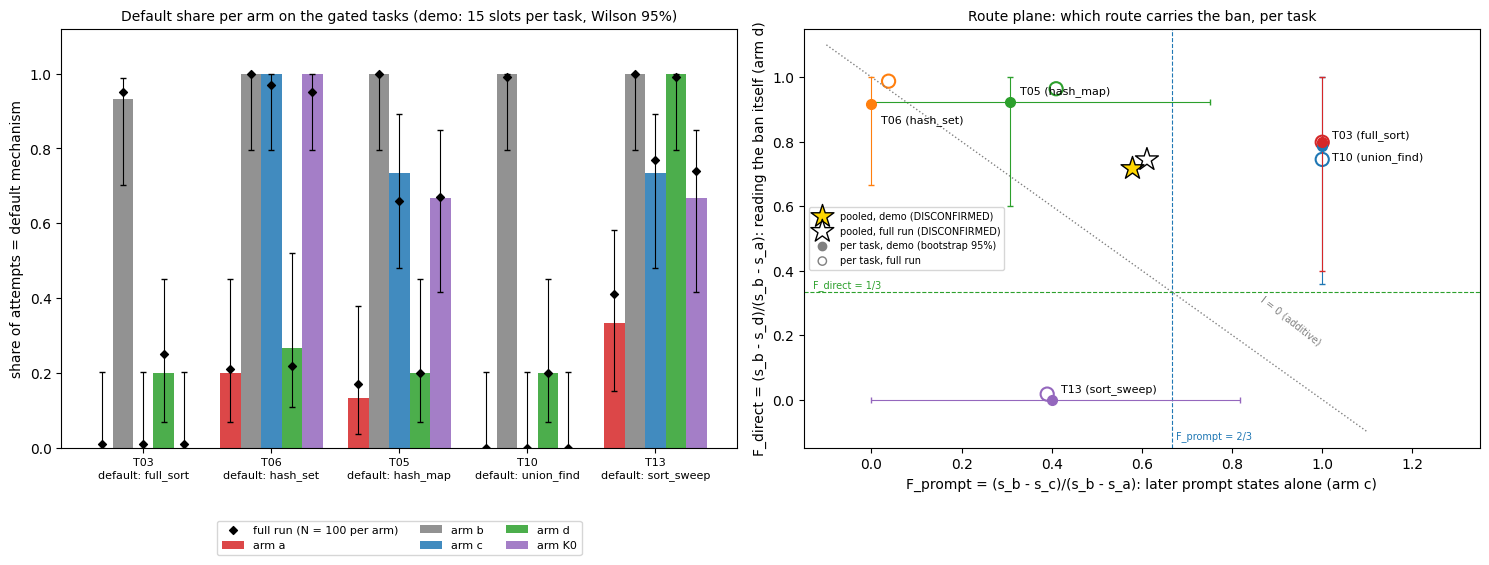

In [23]:
ARM_COL = {"a": "#d62728", "b": "#7f7f7f", "c": "#1f77b4", "d": "#2ca02c", "K0": "#9467bd"}


def _err(p: float, ci: list[float]) -> list[list[float]]:
    # matplotlib error-bar lengths from a point and an interval (NaN-safe, never negative)
    lo, hi = ci
    return [[max(0.0, p - lo) if np.isfinite(lo) else 0.0], [max(0.0, hi - p) if np.isfinite(hi) else 0.0]]


fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))

# (A) default share per arm on the gated tasks: demo subset (bars, Wilson 95%) vs full run (diamonds)
ax = axes[0]
width, x = 0.16, np.arange(len(gated))
for i, a in enumerate(ARMS5):
    s = np.array([shares[t][a]["s"] if a in shares[t] else np.nan for t in gated])
    lo = np.array([shares[t][a]["ci95"][0] if a in shares[t] else np.nan for t in gated])
    hi = np.array([shares[t][a]["ci95"][1] if a in shares[t] else np.nan for t in gated])
    ax.bar(x + (i - 2) * width, s, width, yerr=[np.clip(s - lo, 0, None), np.clip(hi - s, 0, None)], capsize=2,
           color=ARM_COL[a], alpha=0.85, error_kw={"lw": 0.8}, label=f"arm {a}")
    ax.scatter(x + (i - 2) * width, [ref["shares"][t].get(a, np.nan) for t in gated], marker="D", s=16, color="black",
               zorder=3, label="full run (N = 100 per arm)" if i == 0 else None)
ax.set_xticks(x, [f"{t}\ndefault: {DEFAULT[t]}" for t in gated], fontsize=8)
ax.set_ylim(0, 1.12)
ax.set_ylabel("share of attempts = default mechanism")
ax.set_title(f"Default share per arm on the gated tasks (demo: {N_SLOTS * len(TEMPLATE_IDS)} slots per task, Wilson 95%)",
             fontsize=10)
ax.legend(ncol=3, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.16))

# (B) route plane: per-task F_prompt x F_direct (demo with template->slot bootstrap 95%; full run hollow)
ax = axes[1]
ax.plot([-0.1, 1.1], [1.1, -0.1], ls=":", color="grey", lw=1)
ax.text(0.86, 0.17, "I = 0 (additive)", fontsize=7, color="grey", rotation=-38)
ax.axvline(THRESHOLDS["F_confirm"], color="#1f77b4", ls="--", lw=0.8)
ax.axhline(THRESHOLDS["F_direct_disconfirm"], color="#2ca02c", ls="--", lw=0.8)
ax.text(THRESHOLDS["F_confirm"] + 0.01, -0.12, "F_prompt = 2/3", fontsize=7, color="#1f77b4")
ax.text(-0.13, THRESHOLDS["F_direct_disconfirm"] + 0.015, "F_direct = 1/3", fontsize=7, color="#2ca02c")
task_col = dict(zip(gated, plt.cm.tab10(np.arange(len(gated)))))
for i, (t, v) in enumerate(route["per_task"].items()):
    fp, fdr = v["F_prompt"], v["F_direct"]
    ax.errorbar(fp["point"], fdr["point"], xerr=_err(fp["point"], fp["ci95"]), yerr=_err(fdr["point"], fdr["ci95"]),
                fmt="o", ms=7, capsize=2, lw=0.8, color=task_col[t])
    rf = ref["C2a"]["per_task"][t]
    ax.scatter(rf["F_prompt"]["point"], rf["F_direct"]["point"], marker="o", s=90, facecolors="none",
               edgecolors=task_col[t], linewidths=1.5)
    ax.annotate(f"{t} ({DEFAULT[t]})", (fp["point"], fdr["point"]), xytext=(7, 6 if i % 2 == 0 else -13), textcoords="offset points",
                fontsize=8)
pt = route["point"]
ax.scatter(pt["F_prompt"], pt["F_direct"], marker="*", s=300, color="gold", edgecolors="black", zorder=4,
           label=f"pooled, demo ({route['verdict']})")
ax.scatter(ref["C2a"]["point"]["F_prompt"], ref["C2a"]["point"]["F_direct"], marker="*", s=300, facecolors="none",
           edgecolors="black", zorder=4, label=f"pooled, full run ({ref['C2a']['verdict']})")
ax.scatter([], [], marker="o", color="grey", label="per task, demo (bootstrap 95%)")
ax.scatter([], [], marker="o", facecolors="none", edgecolors="grey", label="per task, full run")
ax.set_xlim(-0.15, 1.35)
ax.set_ylim(-0.15, 1.15)
ax.set_xlabel("F_prompt = (s_b - s_c)/(s_b - s_a): later prompt states alone (arm c)")
ax.set_ylabel("F_direct = (s_b - s_d)/(s_b - s_a): reading the ban itself (arm d)")
ax.set_title("Route plane: which route carries the ban, per task", fontsize=10)
ax.legend(fontsize=7, loc="center left")
plt.tight_layout()
plt.show()

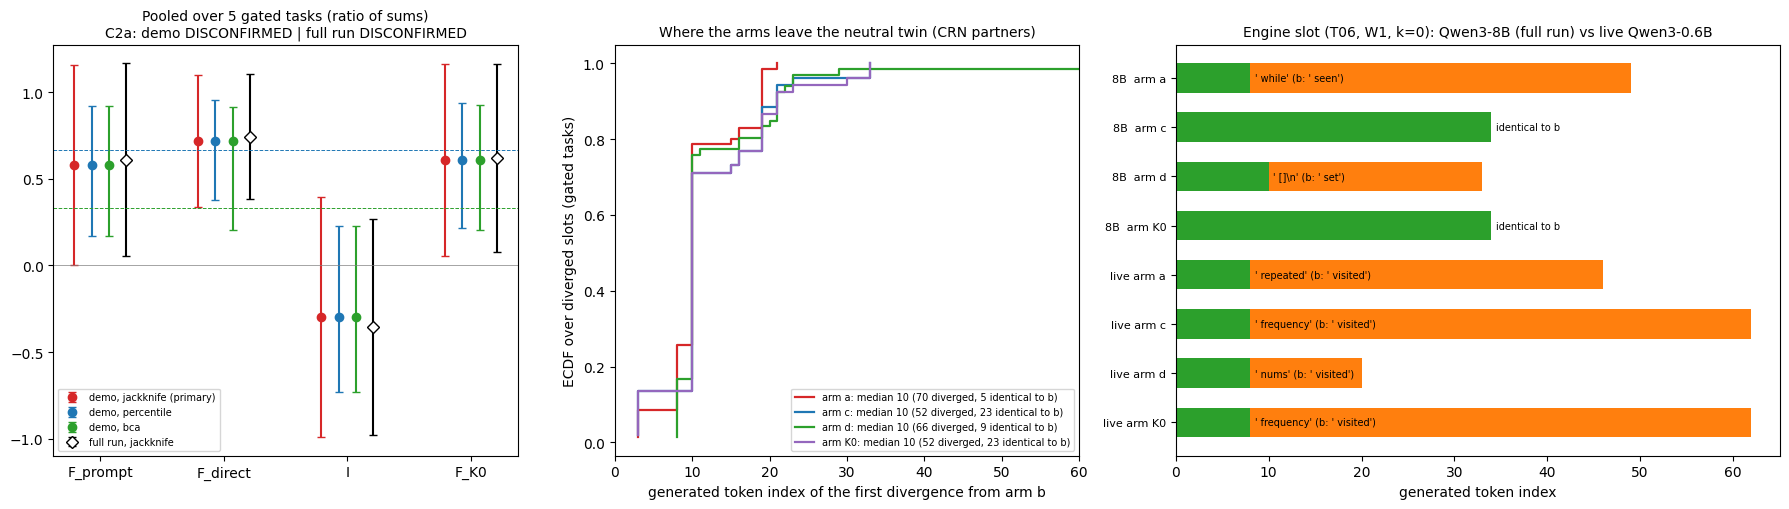

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2), gridspec_kw={"width_ratios": [1, 1, 1.3]})

# (C) pooled route fractions: demo point with jackknife (primary) / percentile / BCa 95%, full run with jackknife 95%
ax = axes[0]
qs = ["F_prompt", "F_direct", "I", "F_K0"]
for j, q in enumerate(qs):
    p = route["point"][q]
    for off, (kind, col) in enumerate([("jackknife", "#d62728"), ("percentile", "#1f77b4"), ("bca", "#2ca02c")]):
        ax.errorbar(j + (off - 1.5) * 0.14, p, yerr=_err(p, route["intervals"][q][kind]), fmt="o", color=col, capsize=3,
                    label=f"demo, {kind}" + (" (primary)" if kind == route["primary_interval"] else "") if j == 0 else None)
    rp = ref["C2a"]["point"][q]
    ax.errorbar(j + 1.5 * 0.14, rp, yerr=_err(rp, ref["C2a"]["intervals"][q]["jackknife"]), fmt="D", color="black",
                mfc="white", capsize=3, label="full run, jackknife" if j == 0 else None)
ax.axhline(THRESHOLDS["F_confirm"], color="#1f77b4", ls="--", lw=0.7)
ax.axhline(THRESHOLDS["F_direct_disconfirm"], color="#2ca02c", ls="--", lw=0.7)
ax.axhline(0, color="grey", lw=0.5)
ax.set_xticks(range(len(qs)), qs)
ax.set_title(f"Pooled over {route['n_tasks']} gated tasks (ratio of sums)\nC2a: demo {route['verdict']} | "
             f"full run {ref['C2a']['verdict']}", fontsize=10)
ax.legend(fontsize=7, loc="lower left")

# (D) first token at which arm X leaves its CRN partner in arm b (Qwen3-8B tokens of the demo slots)
ax = axes[1]
for X in ("a", "c", "d", "K0"):
    vals = np.sort(np.concatenate([np.asarray(crn[t]["first_divergence"].get(X, {}).get("values", []), float)
                                   for t in gated]))
    n_id = sum(crn[t]["first_divergence"].get(X, {}).get("n_identical_to_b", 0) for t in gated)
    if len(vals):
        ax.step(vals, np.arange(1, len(vals) + 1) / len(vals), where="post", color=ARM_COL[X], lw=1.6,
                label=f"arm {X}: median {np.median(vals):.0f} ({len(vals)} diverged, {n_id} identical to b)")
ax.set_xlim(0, 60)
ax.set_xlabel("generated token index of the first divergence from arm b")
ax.set_ylabel("ECDF over diverged slots (gated tasks)")
ax.set_title("Where the arms leave the neutral twin (CRN partners)", fontsize=10)
ax.legend(fontsize=7, loc="lower right")

# (E) the engine slot: token strips identical to arm b (green) until the first divergence (orange after)
ax = axes[2]
k0 = ENGINE_KS[0]
strips = [(f"8B  arm {a}", ref8[str(k0)][a]["token_ids"], ref8[str(k0)]["b"]["token_ids"]) for a in ("a", "c", "d", "K0")]
if RUN_ENGINE:
    strips += [(f"live arm {a}", live[(k0, a)]["token_ids"], live[(k0, "b")]["token_ids"]) for a in ("a", "c", "d", "K0")]
for i, (name, xs, bs) in enumerate(strips):
    d = first_divergence(xs, bs)
    n_same = len(xs) if d is None else d
    ax.barh(i, n_same, color="#2ca02c", height=0.6)
    if d is not None:
        ax.barh(i, len(xs) - d, left=d, color="#ff7f0e", height=0.6)
        if RUN_ENGINE and d < len(xs):
            ax.text(d + 0.5, i, f"{tok.decode([xs[d]])!r} (b: {tok.decode([bs[d]])!r})" if d < len(bs)
                    else f"{tok.decode([xs[d]])!r}", va="center", fontsize=7)
    else:
        ax.text(n_same + 0.5, i, "identical to b", va="center", fontsize=7)
ax.set_yticks(range(len(strips)), [s[0] for s in strips], fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("generated token index")
ax.set_title(f"Engine slot ({eng['task']}, {eng['template']}, k={k0}): Qwen3-8B (full run) vs live "
             f"{ENGINE_MODEL_ID.split('/')[-1] if RUN_ENGINE else '(skipped)'}", fontsize=10)
plt.tight_layout()
plt.show()

In [25]:
# ---- headline numbers: demo subset (100 CRN slots, 500 labelled programs) vs full run (13,030 samples)
def _ci(v: list[float]) -> str:
    return f"[{v[0]:.2f}, {v[1]:.2f}]"


rp = ref["C2a"]
summary = [("gated tasks (frozen gate)", ", ".join(gated), ", ".join(meta["gated_tasks"]))]
for q in ("F_prompt", "F_direct", "I", "F_K0"):
    summary.append((f"pooled {q} [jackknife 95%, primary]",
                    f"{route['point'][q]:.3f} {_ci(route['intervals'][q]['jackknife'])}",
                    f"{rp['point'][q]:.3f} {_ci(rp['intervals'][q]['jackknife'])}"))
summary += [
    ("C2a verdict (percentile / BCa / jackknife)", " / ".join(route["verdict_by_interval"][k] for k in ("percentile", "bca", "jackknife")),
     " / ".join(rp["verdict_by_interval"][k] for k in ("percentile", "bca", "jackknife"))),
    ("P_boot(F_prompt <= 1/2), P_boot(F_direct >= 1/3)",
     f"{route['p_boot_F_prompt_le_half']:.2f}, {route['p_boot_F_direct_ge_third']:.2f}",
     f"{rp['p_boot_F_prompt_le_half']:.2f}, {rp['p_boot_F_direct_ge_third']:.2f}"),
    ("mixed GLM F_prompt, F_direct", f"{route['mixed_glm'].get('F_prompt_glm', float('nan')):.2f}, "
     f"{route['mixed_glm'].get('F_direct_glm', float('nan')):.2f}",
     f"{rp['mixed_glm']['F_prompt_glm']:.2f}, {rp['mixed_glm']['F_direct_glm']:.2f}"),
    ("C2c: hit fraction, Spearman rho (perm p) -> decision",
     f"{c2c['hit_fraction']:.2f}, {c2c['spearman_rho']:.2f} (p {c2c['perm_p_one_sided']:.2f}) -> {c2c['decision']}",
     f"{ref['C2c']['hit_fraction']:.2f}, {ref['C2c']['spearman_rho']:.2f} (p {ref['C2c']['perm_p_one_sided']:.2f}) -> "
     f"{ref['C2c']['decision']}"),
]
for t in gated:
    v, rv = route["per_task"][t], rp["per_task"][t]
    summary.append((f"{t} F_prompt / F_direct", f"{v['F_prompt']['point']:.2f} / {v['F_direct']['point']:.2f}",
                    f"{rv['F_prompt']['point']:.2f} / {rv['F_direct']['point']:.2f}"))
print(pd.DataFrame(summary, columns=["quantity", "demo subset", "full run"]).set_index("quantity").to_string())

                                                                                     demo subset                                    full run
quantity                                                                                                                                    
gated tasks (frozen gate)                                                T03, T06, T05, T10, T13                     T03, T06, T05, T10, T13
pooled F_prompt [jackknife 95%, primary]                                     0.578 [-0.00, 1.16]                          0.611 [0.06, 1.17]
pooled F_direct [jackknife 95%, primary]                                      0.719 [0.34, 1.10]                          0.744 [0.38, 1.11]
pooled I [jackknife 95%, primary]                                           -0.297 [-0.99, 0.40]                        -0.355 [-0.98, 0.27]
pooled F_K0 [jackknife 95%, primary]                                          0.609 [0.06, 1.16]                          0.621 [0.08, 1.16]
C2a verdict (